# Kyiv air alerts: minutes under alert per day, forecast for the next 7 days

**Question.** How many minutes will Kyiv City spend under air-raid alert on each of the next 7 days? The answer is a number per day
with 80% and 95% intervals. Rule of the project: a forecast may use only what was published before it is made.

**Result (snapshot of 12 Oct 2026, 11:02 UTC).** The chosen model, ARIMA(1,1,1) on the square root of daily minutes, forecasts about
**437 minutes per day for 13 to 19 Oct 2026**. The 80% interval runs from about 57 minutes to a whole day (1,440 minutes): at the current
level a full-alert day cannot be ruled out. A combination of ARIMA and a 7-day weighted average, better in the newest level but slightly
worse over the whole test period, gives about 471. Details and caveats in sections 6 to 8.

**Contents**
1. Alerts: the newest Kyiv Digital snapshot, parsed
2. Series at any granularity, with sanity checks
3. Weather and holidays joined by local date; the 7 forecast days
4. Exploration of the data before the test period; four checks on the full history (4b); evidence (4c); decisions (4d)
5. Baselines and rolling-origin backtest: window experiment, intervals, paired tests (5b reading, 5c the best baseline in detail)
6. Models: backtest (6a), choice (6b), forecast combination (6c), intervals (6d), confirmation on the last 14 days (6e)
7. The forecast for the next 7 days
8. Summary, caveats and further work

**Inputs (three separate files, joined here by local date)**
1. Alerts: newest snapshot in `snapshots/`, parsed by `kyiv_digital.py` (Kyiv Digital is the only alert source).
2. Weather: `weather_kyiv_daily.csv` from `weather.py fetch` (Open-Meteo).
3. Holidays: `holiday_features_daily.csv` from `holiday_calendar.py build`.

**Rules**
- All binning goes through `series.minutes_by_bin` (tested), so hourly and daily numbers cannot disagree.
- Section 4 looks only at data **before the first test origin** (`FIRST_TEST_ORIGIN`, 1 Jul 2024). Section 4b deliberately uses the full
  history to describe level shifts; it shaped the kind of model, not its settings (see the caveats in section 8).
- A forecaster at origin t sees only days before t: features, model fits, combination weights and interval errors all use data available
  at t. The tests in `tests/` check this by changing the future and comparing.
- Paired with `analysis.py` (jupytext): edit either file, then run `uv run jupytext --sync analysis.ipynb`.
- Written readings are dated to the snapshot of 12 Oct 2026. A newer snapshot changes the numbers in the tables and plots, not the text.

In [1]:
import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import holiday_calendar as hc
import kyiv_digital as kd
import series as sr
import explore as ex
import backtest as bk
import models as md

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
ROOT = Path.cwd()
assert (ROOT / "kyiv_digital.py").exists(), "start the notebook from the project folder"

In [2]:
# Project constants (change here, nowhere else)
TRAIN_START = "2022-07-01"          # first usable day; earlier months are unreliable (README L9)
HORIZON = 7                         # forecast days after the origin
FIRST_TEST_ORIGIN = pd.Timestamp("2024-07-01")   # a 2-year window is complete from here
EXPLORE_END = FIRST_TEST_ORIGIN - pd.Timedelta(days=1)   # exploration stops here

In [3]:
# Plot style: one colour per meaning, thin marks, quiet grid, readable date axes
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, MaxNLocator

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"          # series 1 and 2 of the reference palette
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 10, "figure.dpi": 110,
})


def date_axis(ax, start, end):
    """Month ticks, every tick labelled with month and year (Jul / 2022)."""
    span = (pd.Timestamp(end) - pd.Timestamp(start)).days
    months = {1: None, 2: [1, 3, 5, 7, 9, 11], 3: [1, 4, 7, 10], 6: [1, 7]}
    step = 1 if span <= 200 else 2 if span <= 500 else 3 if span <= 1900 else 6
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=months[step]))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda x, pos: mdates.num2date(x).strftime("%b\n%Y")))
    ax.grid(axis="x", which="major", color=GRID, linewidth=0.8)
    ax.set_xlim(pd.Timestamp(start), pd.Timestamp(end))


def label(ax, title=None, xlabel=None, ylabel=None):
    ax.set_title(title or "", pad=10)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel or "")

## 1. Alerts

In [4]:
snap = kd.resolve_snapshot([ROOT / "snapshots"])
alerts, anomalies, summary = kd.load(snap)
AS_OF = pd.Timestamp(kd.snapshot_time(snap))        # when the page was downloaded (UTC)
print("snapshot:", snap.name, "| as of", AS_OF, "| local", AS_OF.tz_convert(sr.TZ))
print(len(alerts), "alerts, anomalies:", anomalies)
alerts.tail(3)

snapshot: stats_20261012T110244Z.html | as of 2026-10-12 11:02:44+00:00 | local 2026-10-12 14:02:44+03:00
2690 alerts, anomalies: {'orphan_end': 6, 'double_start': 47, 'open_alert': 0, 'duration_mismatch': 3}


,started_at,finished_at,page_duration_min,duration_min
2687,2026-10-12 02:46:00+00:00,2026-10-12 03:14:00+00:00,28.0,28.0
2688,2026-10-12 03:57:00+00:00,2026-10-12 05:40:00+00:00,102.0,103.0
2689,2026-10-12 07:27:00+00:00,2026-10-12 09:56:00+00:00,148.0,149.0


## 2. Series at any granularity
`minutes_by_bin(alerts, freq, as_of=...)`: `"D"` = local calendar day (23 or 25 hours on clock-change days),
`"h"` = hour, `"15min"` = quarter hour. A running alert counts only until `as_of`.

In [5]:
daily = sr.minutes_by_bin(alerts, "D", as_of=AS_OF, start=TRAIN_START)
hourly = sr.minutes_by_bin(alerts, "h", as_of=AS_OF, start=daily.index[0])   # same first instant as the daily table
last_complete_day = daily.index[daily["complete"]][-1]
print("daily bins:", len(daily), "| hourly bins:", len(hourly), "| last complete day:", last_complete_day.date())
daily.tail(4)

daily bins: 1565 | hourly bins: 37551 | last complete day: 2026-10-11


,minutes,n_starts,bin_minutes,complete
bin_start,,,,
2026-10-09 00:00:00+03:00,719.0,10,1440.0,True
2026-10-10 00:00:00+03:00,792.0,9,1440.0,True
2026-10-11 00:00:00+03:00,325.0,8,1440.0,True
2026-10-12 00:00:00+03:00,280.0,3,1440.0,False


**Columns of the series table** (one row per bin; the index `bin_start` is the start of the bin in Kyiv time)

| column | meaning |
|---|---|
| `minutes` | minutes under alert inside this bin (alerts are clipped at the bin edges) |
| `n_starts` | alerts that **started** in this bin |
| `bin_minutes` | length of the bin itself in minutes: 1440 for a normal day, 1380 or 1500 on clock-change days, 60 for an hour. `minutes / bin_minutes` is the share of time under alert, and `minutes` can never exceed it |
| `complete` | `False` for the bin that is still running at the snapshot time; use only complete bins as actual values |

### Sanity checks (these must pass before anything else is trusted)

In [6]:
t0 = daily.index[0].tz_convert("UTC")
a = alerts[alerts["started_at"] >= t0]
ends = a["finished_at"].where(a["finished_at"].notna() | (a["started_at"] < a["started_at"].max()), AS_OF)   # only the newest may be running
total_from_intervals = (ends - a["started_at"]).dt.total_seconds().sum() / 60     # alerts without an end are skipped
regroup = hourly["minutes"].groupby(hourly.index.tz_convert(sr.TZ).normalize()).sum().reindex(daily.index).fillna(0)
checks = {
    "daily minutes add up to the interval table": abs(daily["minutes"].sum() - total_from_intervals) < 1e-6,
    "hourly minutes regroup to the daily table": np.allclose(regroup.to_numpy(), daily["minutes"].to_numpy()),
    "no bin exceeds its own length": bool((daily["minutes"] <= daily["bin_minutes"] + 1e-9).all()),
    "alert starts counted once": int(daily["n_starts"].sum()) == len(a),
    "only the last day is incomplete (the snapshot day)": int((~daily["complete"]).sum()) == 1,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", name)
assert all(checks.values())

PASS daily minutes add up to the interval table
PASS hourly minutes regroup to the daily table
PASS no bin exceeds its own length
PASS alert starts counted once
PASS only the last day is incomplete (the snapshot day)


## 3. Join weather and holidays by local date

In [7]:
weather = pd.read_csv(ROOT / "weather_kyiv_daily.csv", parse_dates=["date", "sunrise", "sunset"]).set_index("date")
hol_path = ROOT / "holiday_features_daily.csv"
if not hol_path.exists():
    hc.main(["build"])
hol = pd.read_csv(hol_path, parse_dates=["date"]).set_index("date")

data = daily.copy()
data.index = data.index.tz_localize(None)            # local midnights as plain dates
data.index.name = "date"
drop = ["sunrise", "sunset", "source", "fetched_utc"]
data = data.join(weather.drop(columns=drop), how="left").join(hol, how="left")
data["weekday"] = data.index.dayofweek
missing = data.drop(columns=["minutes"]).isna().any(axis=1)
print("rows:", len(data), "| rows with any missing input:", int(missing.sum()))
data.tail(3).T.head(14)

rows: 1565 | rows with any missing input: 0


date,2026-10-10,2026-10-11,2026-10-12
minutes,792.0,325.0,280.0
n_starts,9,8,3
bin_minutes,1440.0,1440.0,1440.0
complete,True,True,False
weather_code,3,95,61
temperature_2m_max,16.9,21.4,16.4
temperature_2m_min,6.7,11.5,10.6
temperature_2m_mean,11.7,16.0,12.2
apparent_temperature_mean,9.6,15.2,11.3
precipitation_sum,0.0,3.0,3.6


### The 7 forecast days (inputs known now: weather forecast and calendar)
`ORIGIN` is the first forecast day. A snapshot taken shortly after midnight (before 06:00 Kyiv time) forecasts from that same day: the day
before is complete and the first minutes of the new day are ignored. A snapshot taken later in the day forecasts from the next midnight;
the snapshot day is then incomplete, so section 7 forecasts it as well and drops it from the table.

In [8]:
AS_OF_LOCAL = AS_OF.tz_convert(sr.TZ)
ORIGIN = (AS_OF_LOCAL.normalize() + pd.Timedelta(days=0 if AS_OF_LOCAL.hour < 6 else 1)).tz_localize(None)
future_days = pd.date_range(ORIGIN, periods=HORIZON, freq="D")
future = weather.loc[future_days].drop(columns=drop).join(hol, how="left")
print("origin:", ORIGIN.date(), "| horizon:", future_days[0].date(), "to", future_days[-1].date())
future[["temperature_2m_mean", "precipitation_sum", "wind_speed_10m_max", "cloud_cover_mean", "daylight_min"]]

origin: 2026-10-13 | horizon: 2026-10-13 to 2026-10-19


,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,cloud_cover_mean,daylight_min
2026-10-13,10.3,1.20,9.3,99,654.144500
2026-10-14,10.0,0.00,11.5,60,650.428833
2026-10-15,9.5,0.00,12.7,42,646.711667
2026-10-16,9.8,0.30,12.0,99,642.995667
2026-10-17,12.0,5.25,9.3,99,639.283500
2026-10-18,10.2,6.50,13.6,100,635.577833
2026-10-19,7.7,4.30,15.3,86,631.881667


## 4. Exploration (only data before `FIRST_TEST_ORIGIN`)

In [9]:
explore = data.loc[:EXPLORE_END]
y = explore["minutes"]
print(f"{len(y)} days | mean {y.mean():.0f} | median {y.median():.0f} | zero-minute days {(y == 0).mean():.1%}")
print(y.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())

731 days | mean 65 | median 29 | zero-minute days 41.9%
count    731.0
mean      64.9
std       90.1
min        0.0
50%       29.0
75%      103.0
90%      182.0
95%      243.0
99%      396.0
max      591.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


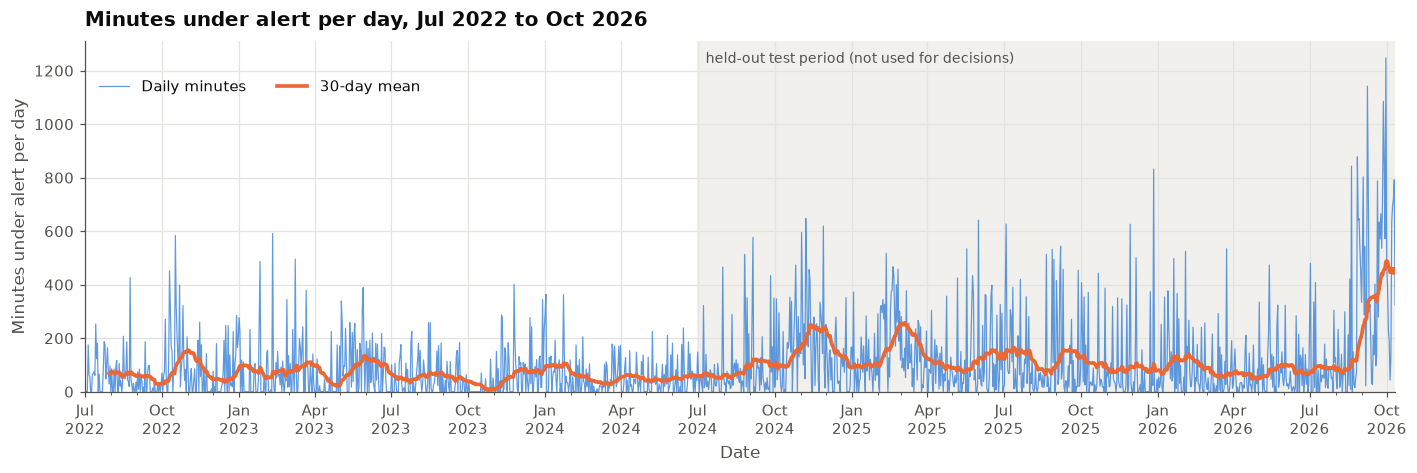

In [10]:
# 1) Daily minutes with a 30-day mean, full history; the held-out test period is shaded
full = data.loc[data["complete"], "minutes"]          # every finished day up to the snapshot
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.plot(full.index, full, color=BLUE, lw=0.8, alpha=0.75, label="Daily minutes")
ax.plot(full.index, full.rolling(30).mean(), color=ORANGE, lw=2.4, label="30-day mean")
ax.axvspan(FIRST_TEST_ORIGIN, full.index[-1], color="#f1f0ec", zorder=0)
ax.text(FIRST_TEST_ORIGIN, 0.97, "  held-out test period (not used for decisions)", transform=ax.get_xaxis_transform(),
        color=MUTED, va="top", fontsize=9)
date_axis(ax, full.index[0], full.index[-1])
ax.set_ylim(0, None)
label(ax, f"Minutes under alert per day, {full.index[0]:%b %Y} to {full.index[-1]:%b %Y}",
      "Date", "Minutes under alert per day")
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 0.93))
plt.tight_layout()

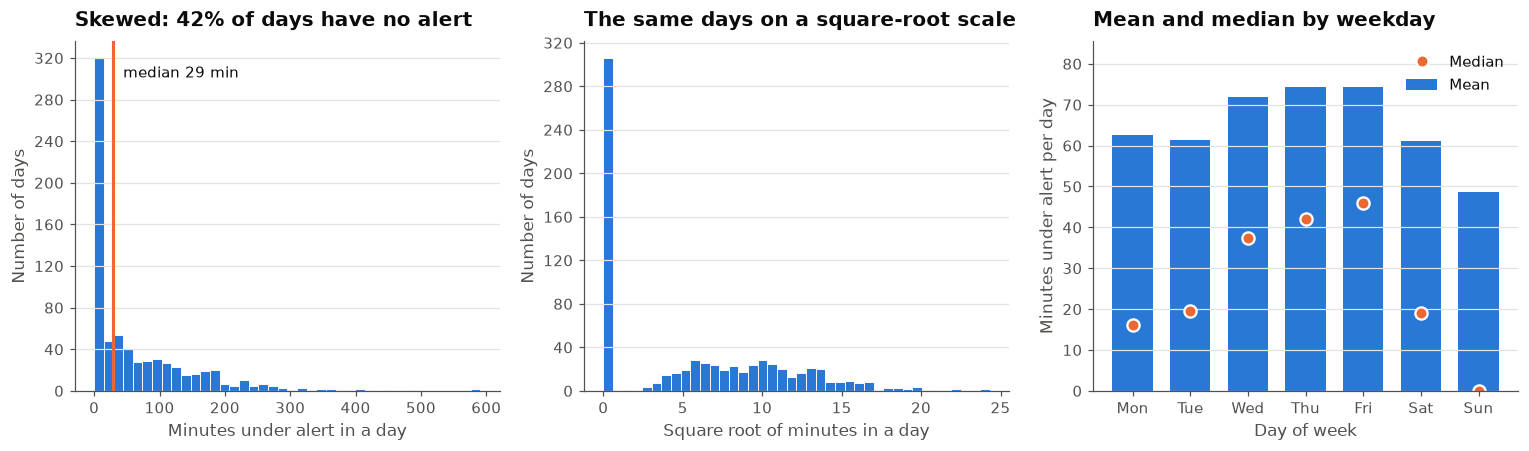

In [11]:
# 2) Shape of the data: raw, square-root scale, and weekday pattern
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].hist(y, bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax[0].axvline(y.median(), color=ORANGE, lw=2)
ax[0].text(y.median(), ax[0].get_ylim()[1] * 0.93, f"  median {y.median():.0f} min", color=INK, va="top")
label(ax[0], f"Skewed: {(y == 0).mean():.0%} of days have no alert", "Minutes under alert in a day", "Number of days")
ax[1].hist(np.sqrt(y), bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
label(ax[1], "The same days on a square-root scale", "Square root of minutes in a day", "Number of days")
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = explore.groupby("weekday")["minutes"].agg(["mean", "median"]).reindex(range(7))
ax[2].bar(range(7), wd["mean"], color=BLUE, width=0.7, label="Mean")
ax[2].plot(range(7), wd["median"], "o", color=ORANGE, ms=8, mec="white", mew=1.5, label="Median")
ax[2].set_xticks(range(7), names)
ax[2].set_ylim(0, wd[["mean", "median"]].to_numpy().max() * 1.15)
label(ax[2], "Mean and median by weekday", "Day of week", "Minutes under alert per day")
ax[2].legend(loc="upper right")
for a_ in ax:
    a_.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()

{1: 0.15, 2: 0.08, 3: 0.02, 4: 0.1, 5: 0.11, 6: 0.11, 7: 0.13}

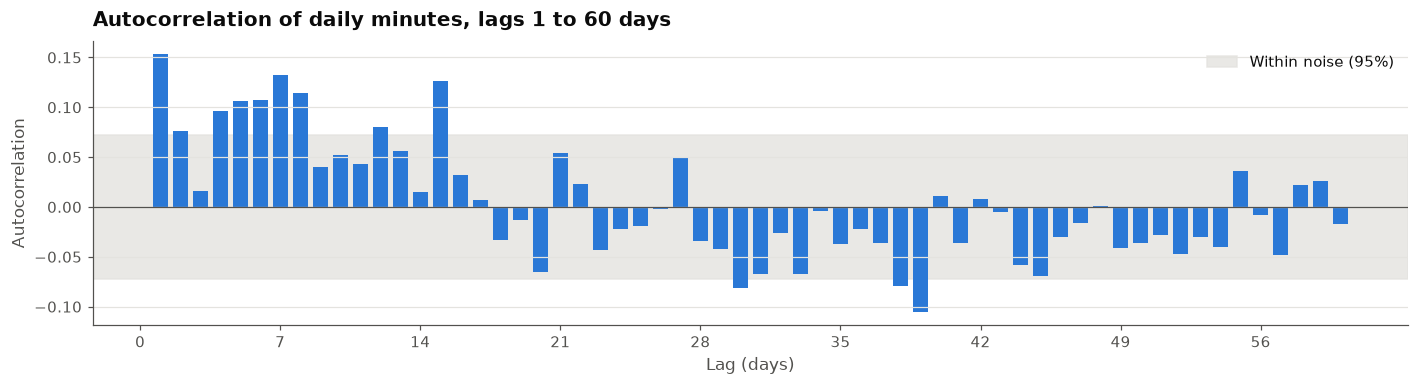

In [12]:
# 3) Persistence: autocorrelation of daily minutes
ac = pd.Series([y.autocorr(k) for k in range(1, 61)], index=range(1, 61))
band = 1.96 / np.sqrt(len(y))
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(ac.index, ac, color=BLUE, width=0.75)
ax.axhspan(-band, band, color=GRID, alpha=0.8, zorder=0, label="Within noise (95%)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(range(0, 61, 7))
label(ax, "Autocorrelation of daily minutes, lags 1 to 60 days",
      "Lag (days)", "Autocorrelation")
ax.legend(loc="upper right")
plt.tight_layout()
ac.head(7).round(2).to_dict()

### 4b. Four checks that decide how we model (full history, test period included)
These are descriptions of the data used to pick the *kind* of model and the training window,
not to tune a model. The held-out period is included on purpose: whether the level shifted
recently is exactly what the older data cannot tell us.
1. **Change points**: did the level move, and when? (training window)
2. **Heavy-day clustering**: do heavy days follow heavy days beyond what slow level changes explain? (use of recent days)
3. **Count vs duration**: is a heavy day many alerts or long alerts? (later split into Q1 and Q3)
4. **Spread against level**: does day-to-day scatter grow with the level? (scale for the intervals)

,from,to,days,mean,median,zero_days
0,2022-07-01,2024-08-10,772,64.49,29.0,0.41
1,2024-08-11,2026-08-26,746,114.36,56.0,0.21
2,2026-08-27,2026-10-11,46,485.37,491.0,0.00


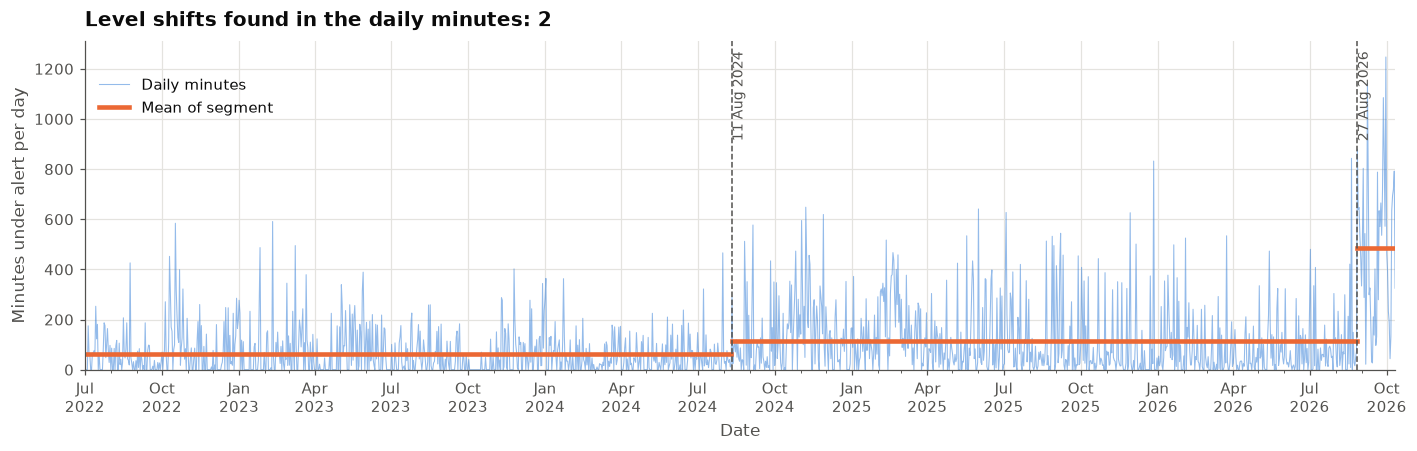

In [13]:
# 1) Change points on the square-root scale (square root tames the skew and the zero days)
full = data.loc[data["complete"]]
yf = full["minutes"]
cps = ex.change_points(np.sqrt(yf.to_numpy()), min_size=45, strength=10)
bounds = [0] + cps + [len(yf)]
seg = pd.DataFrame([{"from": yf.index[a].date(), "to": yf.index[b - 1].date(), "days": b - a,
                     "mean": yf.iloc[a:b].mean(), "median": yf.iloc[a:b].median(),
                     "zero_days": (yf.iloc[a:b] == 0).mean()} for a, b in zip(bounds[:-1], bounds[1:])]).round(2)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(yf.index, yf, color=BLUE, lw=0.7, alpha=0.5, label="Daily minutes")
for i, (a, b) in enumerate(zip(bounds[:-1], bounds[1:])):
    ax.plot(yf.index[a:b], np.full(b - a, yf.iloc[a:b].mean()), color=ORANGE, lw=3, label="Mean of segment" if i == 0 else None)
for k in cps:
    ax.axvline(yf.index[k], color=MUTED, lw=1, ls="--")
    ax.text(yf.index[k], ax.get_ylim()[1] * 0.97, f" {yf.index[k]:%d %b %Y}", color=MUTED, rotation=90, va="top", fontsize=9)
date_axis(ax, yf.index[0], yf.index[-1])
ax.set_ylim(0, None)
label(ax, f"Level shifts found in the daily minutes: {len(cps)}", "Date", "Minutes under alert per day")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.93))
plt.tight_layout()
seg

Heavy-day threshold (top 10% of all days): 287 min


,p_given_heavy_all,lift_all,p_given_heavy_local,lift_local
lag,,,,
1,0.33,3.32,0.17,1.71
2,0.28,2.76,0.11,1.08
3,0.26,2.59,0.11,1.14
4,0.29,2.93,0.13,1.27
5,0.24,2.36,0.10,0.95
6,0.26,2.56,0.08,0.76
7,0.28,2.75,0.13,1.27


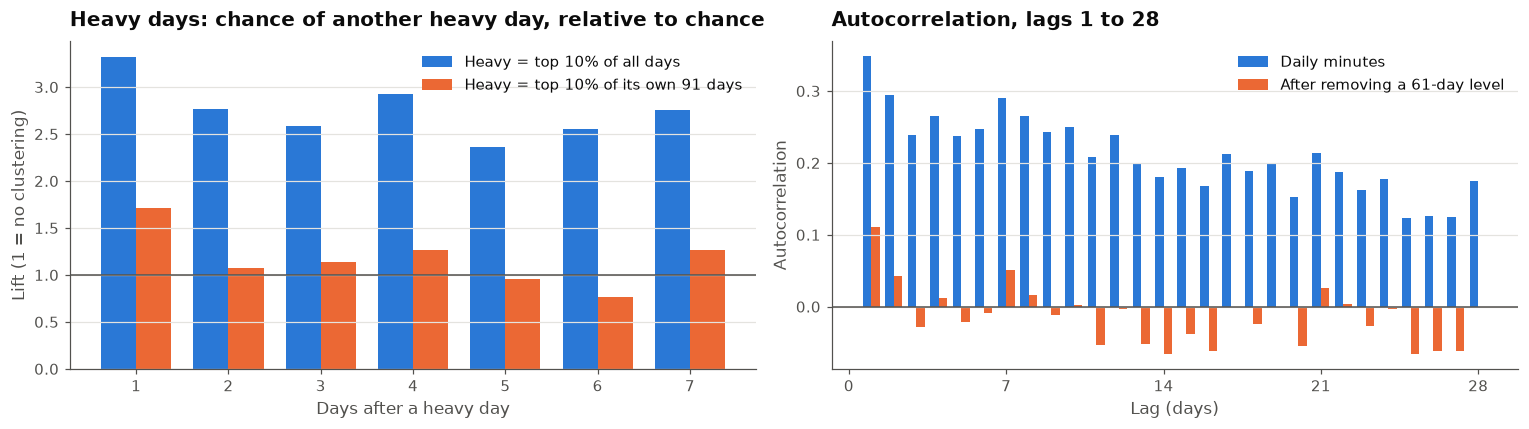

In [14]:
# 2) Heavy-day clustering: lift = P(heavy k days later | heavy today) / P(heavy). 1 means no clustering.
lift_all = ex.heavy_lift(yf, 0.9)
lift_loc = ex.heavy_lift(yf, 0.9, local_window=91)
ac_raw, ac_det = ex.acf(yf, 28), ex.acf(yf, 28, detrend_window=61)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
w = 0.38
ax[0].bar(lift_all["lag"] - w / 2, lift_all["lift"], width=w, color=BLUE, label="Heavy = top 10% of all days")
ax[0].bar(lift_loc["lag"] + w / 2, lift_loc["lift"], width=w, color=ORANGE, label="Heavy = top 10% of its own 91 days")
ax[0].axhline(1, color=MUTED, lw=1)
ax[0].set_xticks(range(1, 8))
label(ax[0], "Heavy days: chance of another heavy day, relative to chance", "Days after a heavy day", "Lift (1 = no clustering)")
ax[0].legend(loc="upper right")
ax[1].bar(ac_raw.index - w / 2, ac_raw, width=w, color=BLUE, label="Daily minutes")
ax[1].bar(ac_det.index + w / 2, ac_det, width=w, color=ORANGE, label="After removing a 61-day level")
ax[1].axhline(0, color=MUTED, lw=1)
ax[1].set_xticks(range(0, 29, 7))
label(ax[1], "Autocorrelation, lags 1 to 28", "Lag (days)", "Autocorrelation")
ax[1].legend(loc="upper right")
plt.tight_layout()
print(f"Heavy-day threshold (top 10% of all days): {yf.quantile(.9):.0f} min")
pd.concat([lift_all.set_index("lag")[["p_given_heavy", "lift"]].add_suffix("_all"),
           lift_loc.set_index("lag")[["p_given_heavy", "lift"]].add_suffix("_local")], axis=1).round(2)

Share of the variation in log minutes that comes from the number of alerts: 34%; from minutes per alert: 66%


,minutes,alerts,min_per_alert
decile,,,
0,16.0,1.0,15.5
1,26.0,1.0,26.0
2,40.0,1.0,35.0
3,56.0,1.0,49.0
4,78.0,2.0,40.8
5,105.0,2.0,53.2
6,137.0,2.0,68.0
7,183.0,2.0,88.5
8,279.0,2.0,116.5


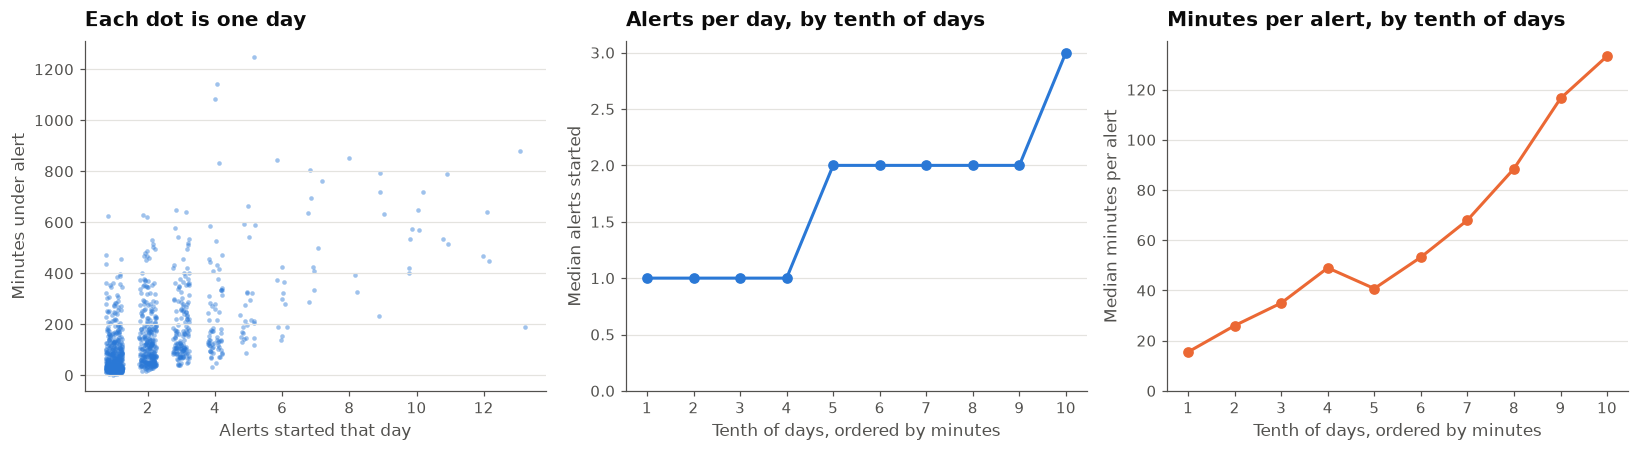

In [15]:
# 3) Count vs duration: minutes = (alerts that started) x (minutes per alert), on days with at least one start
cd = full[(full["n_starts"] > 0) & (full["minutes"] > 0)].copy()
cd["min_per_alert"] = cd["minutes"] / cd["n_starts"]
lm, ln, la = np.log(cd["minutes"]), np.log(cd["n_starts"]), np.log(cd["min_per_alert"])
share_n, share_d = np.cov(lm, ln)[0, 1] / lm.var(), np.cov(lm, la)[0, 1] / lm.var()
cd["decile"] = pd.qcut(cd["minutes"], 10, labels=False)
by = cd.groupby("decile").agg(minutes=("minutes", "median"), alerts=("n_starts", "median"), min_per_alert=("min_per_alert", "median"))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
jit = np.random.default_rng(0).uniform(-0.25, 0.25, len(cd))
ax[0].scatter(cd["n_starts"] + jit, cd["minutes"], s=9, color=BLUE, alpha=0.45, linewidths=0)
label(ax[0], "Each dot is one day", "Alerts started that day", "Minutes under alert")
ax[1].plot(by.index + 1, by["alerts"], "o-", color=BLUE, lw=2, ms=6)
ax[1].set_xticks(range(1, 11))
ax[1].set_ylim(0, None)
label(ax[1], "Alerts per day, by tenth of days", "Tenth of days, ordered by minutes", "Median alerts started")
ax[2].plot(by.index + 1, by["min_per_alert"], "o-", color=ORANGE, lw=2, ms=6)
ax[2].set_xticks(range(1, 11))
ax[2].set_ylim(0, None)
label(ax[2], "Minutes per alert, by tenth of days", "Tenth of days, ordered by minutes", "Median minutes per alert")
plt.tight_layout()
print(f"Share of the variation in log minutes that comes from the number of alerts: {share_n:.0%}; from minutes per alert: {share_d:.0%}")
by.round(1)

52 blocks, slope of log std on log mean: 0.70 (0 = spread ignores level, 1 = proportional to level)


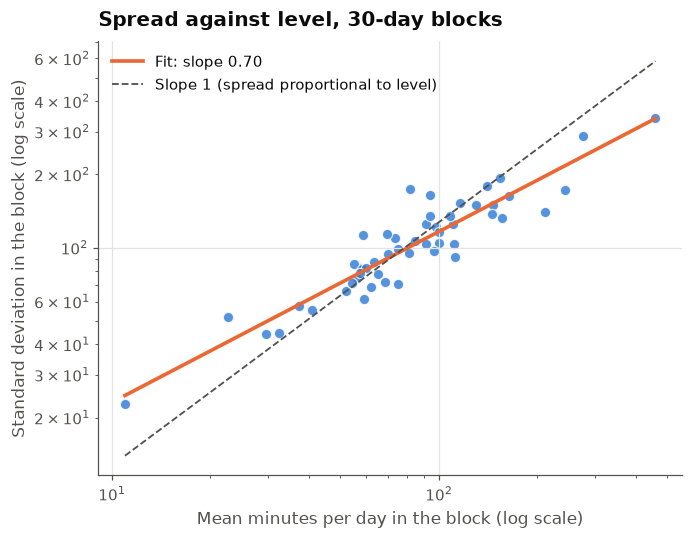

In [16]:
# 4) Spread against level, on non-overlapping 30-day blocks
blk, slope = ex.dispersion_blocks(yf, 30)
ok = (blk["mean"] > 0) & (blk["std"] > 0)
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.scatter(blk.loc[ok, "mean"], blk.loc[ok, "std"], s=45, color=BLUE, alpha=0.8, edgecolor="white", linewidth=0.8)
xs = np.array([blk.loc[ok, "mean"].min(), blk.loc[ok, "mean"].max()])
c0 = np.exp(np.log(blk.loc[ok, "std"]).mean() - slope * np.log(blk.loc[ok, "mean"]).mean())
ax.plot(xs, c0 * xs ** slope, color=ORANGE, lw=2.4, label=f"Fit: slope {slope:.2f}")
ax.plot(xs, blk.loc[ok, "std"].median() * (xs / blk.loc[ok, "mean"].median()), color=MUTED, lw=1.2, ls="--", label="Slope 1 (spread proportional to level)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(axis="x", color=GRID, linewidth=0.8)
label(ax, "Spread against level, 30-day blocks", "Mean minutes per day in the block (log scale)", "Standard deviation in the block (log scale)")
ax.legend(loc="upper left")
plt.tight_layout()
print(f"{int(ok.sum())} blocks, slope of log std on log mean: {slope:.2f} (0 = spread ignores level, 1 = proportional to level)")

### 4c. Evidence from the exploration (computed from the data above)

In [17]:
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd_mean = explore.groupby("weekday")["minutes"].mean()
rows = [
    ("Series", f"{len(yf)} complete days, {yf.index[0]:%d %b %Y} to {yf.index[-1]:%d %b %Y}; mean {yf.mean():.0f}, median {yf.median():.0f} min/day; "
               f"{(yf == 0).mean():.0%} of days with no alert"),
    ("Level shifts", f"{len(cps)} found. " + "; ".join(
        f"{r['from']:%d %b %Y} to {r['to']:%d %b %Y}: mean {r['mean']:.0f}, median {r['median']:.0f}, {r['zero_days']:.0%} zero days, {r['days']} days"
        for _, r in seg.assign(**{"from": pd.to_datetime(seg["from"]), "to": pd.to_datetime(seg["to"])}).iterrows())),
    ("Weekday (before test period)", f"mean minutes: highest {names[int(wd_mean.idxmax())]} {wd_mean.max():.0f}, lowest {names[int(wd_mean.idxmin())]} {wd_mean.min():.0f}"),
    ("Persistence", f"autocorrelation at lag 1 {ac_raw[1]:.2f}, after removing a 61-day level {ac_det[1]:.2f}; lag 7 {ac_raw[7]:.2f} and {ac_det[7]:.2f}"),
    ("Heavy-day clustering", f"heavy = above {yf.quantile(.9):.0f} min (top 10%). Lift at lags 1 to 7: all-history threshold "
                             + ", ".join(f"{v:.1f}" for v in lift_all["lift"]) + "; local 91-day threshold " + ", ".join(f"{v:.1f}" for v in lift_loc["lift"])),
    ("Count vs duration", f"share of variation in log minutes from minutes per alert {share_d:.0%}, from number of alerts {share_n:.0%}; "
                          f"lightest tenth of days: {by['alerts'].iloc[0]:.0f} alert of {by['min_per_alert'].iloc[0]:.0f} min, heaviest tenth: {by['alerts'].iloc[-1]:.0f} alerts of {by['min_per_alert'].iloc[-1]:.0f} min"),
    ("Spread against level", f"slope of log standard deviation on log mean {slope:.2f} over {int(ok.sum())} blocks of 30 days (about Tweedie power {2 * slope:.1f})"),
]
for k, v in rows:
    print(f"{k}\n    {v}\n")

Series
    1564 complete days, 01 Jul 2022 to 11 Oct 2026; mean 101, median 44 min/day; 30% of days with no alert

Level shifts
    2 found. 01 Jul 2022 to 10 Aug 2024: mean 64, median 29, 41% zero days, 772 days; 11 Aug 2024 to 26 Aug 2026: mean 114, median 56, 21% zero days, 746 days; 27 Aug 2026 to 11 Oct 2026: mean 485, median 491, 0% zero days, 46 days

Weekday (before test period)
    mean minutes: highest Fri 74, lowest Sun 49

Persistence
    autocorrelation at lag 1 0.35, after removing a 61-day level 0.11; lag 7 0.29 and 0.05

Heavy-day clustering
    heavy = above 287 min (top 10%). Lift at lags 1 to 7: all-history threshold 3.3, 2.8, 2.6, 2.9, 2.4, 2.6, 2.8; local 91-day threshold 1.7, 1.1, 1.1, 1.3, 1.0, 0.8, 1.3

Count vs duration
    share of variation in log minutes from minutes per alert 66%, from number of alerts 34%; lightest tenth of days: 1 alert of 16 min, heaviest tenth: 3 alerts of 133 min

Spread against level
    slope of log standard deviation on log mean 0.7

### 4d. What we take from it, and how each point is validated
The numbers above are from the snapshot of 12 Oct 2026; the reading below is written for that snapshot.

**What the evidence says**
- The level of minutes under alert has shifted, and the newest level is several times the older ones. Old data describes a different regime.
- Heavy days follow the *level*; after removing the level only the next day carries a little extra information.
- Heavy days are mostly long alerts, and the scatter grows with the level, so intervals must scale with the level.

**Decisions**
1. **Recent level as the main input.** Features from the latest values only: yesterday, trailing 7-, 14- and 30-day means and medians, an exponentially weighted average. These are also the baselines every other model must beat.
2. **Test whether old data helps.** Same model, same backtest origins, different training windows (30, 60, 90, 180, 365, 730 days and the whole history, plus decayed weights and "since the last break"). Plot the metric against window length: if it stops improving, or gets worse, beyond some length, the older data is not helping and is dropped. Report the result per slice (before Aug 2024, Aug 2024 to Aug 2026, last 46 days), because the newest level has almost no history.
3. **Transformed target and scaled intervals.** Square-root or log scale, or a Tweedie model, with interval widths that grow with the level; check coverage of the 80% and 95% bands per horizon.
4. **Weekday, then weather and holidays**, one group at a time, with and without, on the same backtest.
5. **Guard against another shift**: combine a short-window and a longer-window forecast and compare with the best single one.

Every feature is built from `series.as_of_view` only, so nothing known after the forecast origin leaks in.

## 5. Baselines and rolling-origin backtest
Forecast origin = each local midnight from `FIRST_TEST_ORIGIN`; the forecaster sees only days before the origin
and predicts the next 7 days (horizon 1 to 7). Methods are simple, recent-level forecasters: yesterday, same weekday,
trailing mean and median over W days, exponentially weighted mean, and "since the last detected break".
The same method with different W **is** the window experiment: if a longer window does not help, the older data is not helping.
Headline metric MAE in minutes (MASE = MAE / the mean day-to-day change before the test period). Median methods also give
80% and 95% intervals from the same W days. Slices are by target date, using the level shifts found in 4b (for reporting only).

In [18]:
y_all = data.loc[data["complete"], "minutes"]
ORIGINS = pd.date_range(FIRST_TEST_ORIGIN, y_all.index[-1] - pd.Timedelta(days=HORIZON - 1))
bt = bk.run_backtest(y_all, ORIGINS, HORIZON)
SCALE = bk.naive_scale(y_all.loc[:EXPLORE_END])
edges = [pd.Timestamp("2000-01-01")] + [yf.index[k] for k in cps] + [pd.Timestamp("2100-01-01")]
d1 = pd.Timedelta(days=1)
slice_names = [f"before {edges[1]:%d %b %Y}"] + [f"{edges[i]:%d %b %Y} to {edges[i + 1] - d1:%d %b %Y}" for i in range(1, len(edges) - 2)] \
              + [f"from {edges[-2]:%d %b %Y}"]
bt["slice"] = pd.cut(bt["target"], edges, right=False, labels=slice_names)
bt["origin_slice"] = pd.cut(bt["origin"], edges, right=False, labels=slice_names)
print(f"{len(ORIGINS)} origins, {ORIGINS[0]:%d %b %Y} to {ORIGINS[-1]:%d %b %Y}, {bt['method'].nunique()} methods, MASE unit {SCALE:.1f} min")
print(bt.groupby("slice", observed=True)["target"].nunique().rename("target days per slice").to_string())

827 origins, 01 Jul 2024 to 05 Oct 2026, 29 methods, MASE unit 79.1 min
slice
before 11 Aug 2024             41
11 Aug 2024 to 26 Aug 2026    746
from 27 Aug 2026               46


In [19]:
# Leaderboard: all methods, overall and per slice (MAE in minutes)
overall = bk.score(bt, SCALE)
by_slice = bk.score(bt, SCALE, ["method", "slice"])["mae"].unstack()
board = overall.join(by_slice.add_prefix("MAE ")).sort_values("mae")
board.round(1)

,mae,mase,rmse,bias,n,MAE before 11 Aug 2024,MAE 11 Aug 2024 to 26 Aug 2026,MAE from 27 Aug 2026
method,,,,,,,,
median_30,105.3,1.3,172.1,-54.2,5789,47.1,95.0,336.8
median_14,106.0,1.3,171.2,-46.2,5789,47.5,94.1,363.4
median_60,108.5,1.4,181.1,-64.1,5789,45.7,95.8,384.2
median_7,109.0,1.4,171.7,-40.6,5789,48.5,98.2,348.8
median_90,109.7,1.4,184.8,-66.8,5789,45.3,95.6,411.4
ewma_7,111.4,1.4,158.7,-6.9,5789,54.2,102.9,308.2
ewma_14,111.8,1.4,160.0,-10.9,5789,52.8,103.3,310.8
mean_30,111.9,1.4,159.8,-9.6,5789,53.0,103.8,303.5
median_180,112.0,1.4,189.2,-72.2,5789,45.2,96.6,436.7


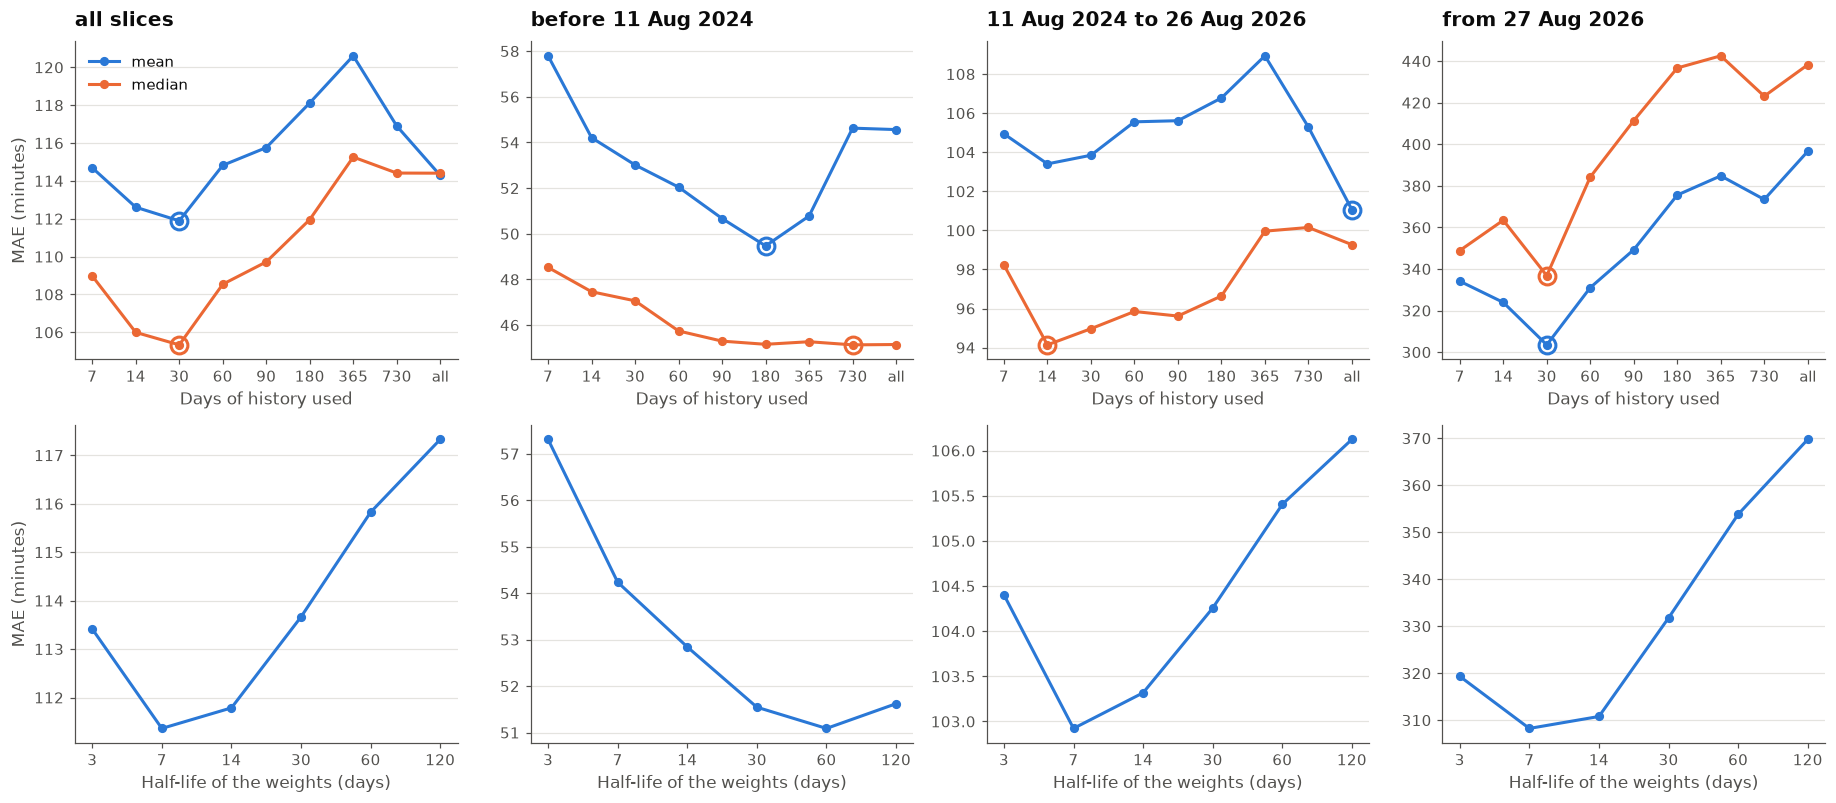

In [20]:
# Window experiment: error against how much history the forecaster uses
wins = list(bk.WINDOWS)
xl = ["all" if w is None else str(w) for w in wins]
groups = [("all slices", None)] + [(n, n) for n in slice_names]
fig, ax = plt.subplots(2, len(groups), figsize=(4.2 * len(groups), 7.4))
for j, (title, sl) in enumerate(groups):
    sc = overall["mae"] if sl is None else by_slice[sl]
    for kind, col in (("mean", BLUE), ("median", ORANGE)):
        vals = [sc[f"{kind}_{t}"] for t in xl]
        ax[0, j].plot(range(len(xl)), vals, "o-", color=col, lw=2, ms=5, label=kind)
        k = int(np.argmin(vals))
        ax[0, j].plot(k, vals[k], "o", ms=11, mfc="none", mec=col, mew=2)
    ax[0, j].set_xticks(range(len(xl)), xl)
    label(ax[0, j], title, "Days of history used", "MAE (minutes)" if j == 0 else "")
    hl = list(bk.HALF_LIVES)
    ax[1, j].plot(range(len(hl)), [sc[f"ewma_{h}"] for h in hl], "o-", color=BLUE, lw=2, ms=5, label="exp. weighted mean")
    ax[1, j].set_xticks(range(len(hl)), hl)
    label(ax[1, j], "", "Half-life of the weights (days)", "MAE (minutes)" if j == 0 else "")
ax[0, 0].legend(loc="best")
plt.tight_layout()

In [21]:
# By horizon: does the forecast get worse further out? MAE for a few methods, overall and in the newest slice
pick = ["last", "same_weekday", "mean_7", "mean_30", "median_30", "ewma_7", "mean_all"]
hz = bk.score(bt[bt["method"].isin(pick)], SCALE, ["method", "h"])["mae"].unstack().loc[pick]
hz_new = bk.score(bt[bt["method"].isin(pick) & (bt["slice"] == slice_names[-1])], SCALE, ["method", "h"])["mae"].unstack().loc[pick]
print("MAE by horizon, all test days"); print(hz.round(0).to_string())
print(f"\nMAE by horizon, {slice_names[-1]}"); print(hz_new.round(0).to_string())

MAE by horizon, all test days
h                 1      2      3      4      5      6      7
method                                                       
last          135.0  136.0  145.0  139.0  143.0  142.0  140.0
same_weekday  138.0  138.0  139.0  139.0  140.0  140.0  140.0
mean_7        113.0  114.0  114.0  114.0  115.0  116.0  117.0
mean_30       110.0  111.0  111.0  112.0  112.0  113.0  114.0
median_30     102.0  103.0  105.0  105.0  106.0  107.0  108.0
ewma_7        109.0  111.0  111.0  111.0  112.0  113.0  113.0
mean_all      113.0  113.0  114.0  114.0  115.0  116.0  116.0

MAE by horizon, from 27 Aug 2026
h                 1      2      3      4      5      6      7
method                                                       
last          275.0  303.0  330.0  385.0  396.0  383.0  387.0
same_weekday  388.0  389.0  394.0  390.0  389.0  393.0  387.0
mean_7        291.0  324.0  333.0  347.0  351.0  345.0  343.0
mean_30       294.0  299.0  303.0  306.0  307.0  308.0  306.0
median

,cov80,cov95,width80,width95,is80,is95
method,,,,,,
median_14,0.72,0.87,267.20,388.77,526.30,868.36
median_180,0.85,0.95,301.50,456.44,555.06,799.11
median_30,0.83,0.94,295.12,432.72,515.35,750.83
median_365,0.84,0.94,296.82,456.00,569.26,815.71
median_60,0.85,0.94,314.65,455.09,515.47,745.69
median_7,0.64,0.73,238.17,316.17,568.04,1213.40
median_730,0.82,0.92,271.36,422.77,577.87,856.55
median_90,0.86,0.94,310.03,461.65,522.16,765.79
median_all,0.79,0.91,236.05,397.07,604.12,938.13


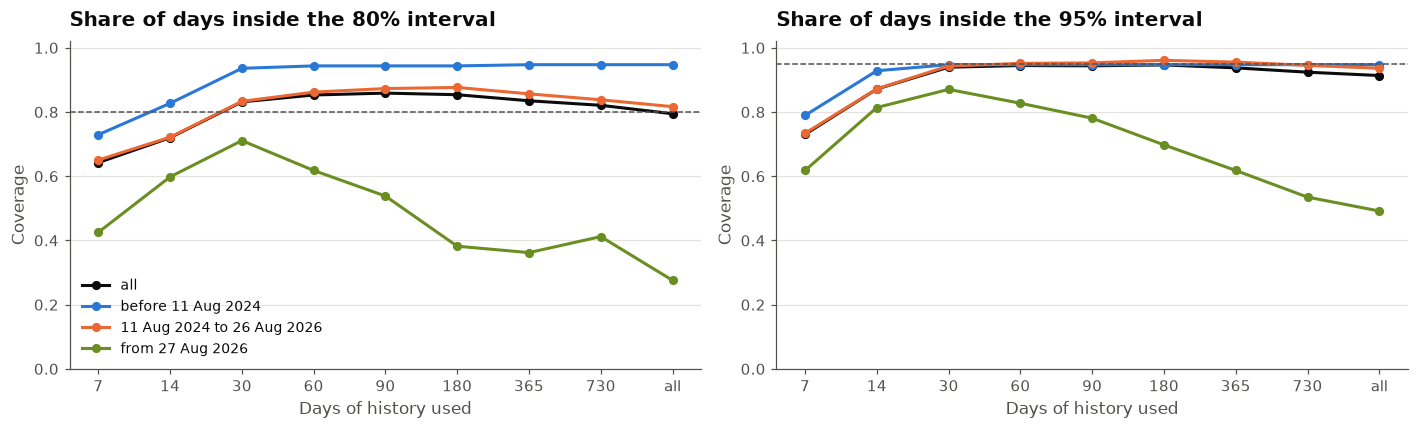

In [22]:
# Intervals from the same W days: do the 80% and 95% bands cover what they should?
iv = bk.interval_score(bt, ["method"])
iv_sl = bk.interval_score(bt, ["method", "slice"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, (lvl, nominal) in enumerate(((80, 0.8), (95, 0.95))):
    for sl, col in zip(["all"] + slice_names, [INK, BLUE, ORANGE, "#6b8e23"]):
        vals = [(iv if sl == "all" else iv_sl.xs(sl, level="slice"))[f"cov{lvl}"].get(f"median_{t}", np.nan) for t in xl]
        ax[j].plot(range(len(xl)), vals, "o-", color=col, lw=2, ms=5, label=sl)
    ax[j].axhline(nominal, color=MUTED, lw=1, ls="--")
    ax[j].set_xticks(range(len(xl)), xl)
    ax[j].set_ylim(0, 1.02)
    label(ax[j], f"Share of days inside the {lvl}% interval", "Days of history used", "Coverage")
ax[0].legend(loc="lower left", fontsize=9)
plt.tight_layout()
iv[["cov80", "cov95", "width80", "width95", "is80", "is95"]].round(2)

In [23]:
# Does old data help? Paired comparison per origin (mean absolute error over the 7 days), Diebold-Mariano with Newey-West errors.
# a minus b: a positive mean means the first method is worse. No correction for the number of comparisons: exploratory.
loss = bt.assign(ae=(bt["point"] - bt["y"]).abs()).groupby(["method", "origin"])["ae"].mean().unstack(0)
orig_sl = bt.drop_duplicates("origin").set_index("origin")["origin_slice"]
pairs = [("mean_all", "mean_30"), ("mean_365", "mean_30"), ("mean_90", "mean_30"), ("mean_7", "mean_30"),
         ("median_all", "median_30"), ("median_365", "median_30"), ("ewma_7", "mean_30"), ("last", "mean_30")]
rows = []
for a_, b_ in pairs:
    for name, mask in [("all test origins", slice(None))] + [(n, orig_sl == n) for n in slice_names]:
        la, lb = (loss[a_], loss[b_]) if name == "all test origins" else (loss.loc[mask, a_], loss.loc[mask, b_])
        mu, st, p = bk.dm_test(la.to_numpy(), lb.to_numpy(), lags=HORIZON - 1)
        rows.append({"a (first)": a_, "b (second)": b_, "origins from": name, "n": len(la), "mean diff a-b (min)": mu, "p-value": p})
pd.DataFrame(rows).round(3)

,a (first),b (second),origins from,n,mean diff a-b (min),p-value
0,mean_all,mean_30,all test origins,827,2.398,0.464
1,mean_all,mean_30,before 11 Aug 2024,41,1.098,0.014
2,mean_all,mean_30,11 Aug 2024 to 26 Aug 2026,746,-2.657,0.182
3,mean_all,mean_30,from 27 Aug 2026,40,98.017,0.014
4,mean_365,mean_30,all test origins,827,8.717,0.004
5,mean_365,mean_30,before 11 Aug 2024,41,-2.038,0.000
6,mean_365,mean_30,11 Aug 2024 to 26 Aug 2026,746,5.181,0.008
7,mean_365,mean_30,from 27 Aug 2026,40,85.678,0.025
8,mean_90,mean_30,all test origins,827,3.867,0.079
9,mean_90,mean_30,before 11 Aug 2024,41,-2.203,0.001


### 5b. Reading of the backtest (snapshot of 12 Oct 2026; numbers are in the tables and plots above)
**Do recent values beat the whole history?** Yes where it matters, and it does not matter much elsewhere.
- Over all 827 test origins the spread between windows is small (MAE about 105 to 121 minutes) because most test days fall in the middle level.
  Whole history against 30 days is a tie there (mean difference 2 minutes, p = 0.46).
- In the newest level (from 27 Aug 2026) the whole history is clearly worse: MAE 397 against 304 for the 30-day mean (+98 minutes, p = 0.014),
  and 438 against 337 for the median (+108, p = 0.009). Error is lowest at about 30 days and higher with longer windows.
- In the first 41 days (stable low level) windows up to about 180 days do better than short ones, so old data helps only while the level stays put.
- An exponentially weighted mean with a half-life of 7 days is the best mean-type forecaster overall (MAE 111) and within 2 minutes of the best one in the middle level and 5 in the newest.

**Simple baselines.** Yesterday and the same weekday last week are clearly worse than a 30-day mean (about +28 minutes, p < 0.001).
The mean of the same weekday over the last 4 weeks (MAE 121) is worse than the plain 30-day mean (112), so the weekday pattern does not help in this simple form.

**Point forecast: median or mean?** Median methods win on MAE but are biased low (about -54 minutes) on this skewed series; mean methods win on RMSE
(about 159 against 172). The MAE headline favours the median; if totals matter, the mean is the safer choice.

**Horizon.** Flat level forecasts hardly get worse from day 1 to day 7 (30-day mean: 110 to 114). In the newest level, "yesterday" degrades
from 275 to 387 across the horizon while the 30-day mean stays near 300.

**"Since the last break" is not the answer.** The break detector needs about 45 days to see a new level, so it is no better than the long windows
exactly when it is needed (MAE 361 and 400 in the newest slice).

**Intervals.** Bands built from the last 30 to 90 days cover about as they should over the whole test period (30 days: 83% and 94% for the 80% and 95% bands).
In the newest level they break down: the 30-day band covers 71% and 87%, the whole-history band only 28% and 49%. In this level the daily standard deviation is
about 306 minutes around a mean of 485, so even a forecaster who knew the level exactly would have an error of the order of 250 minutes. Our best MAE of about 300 is
not far above that floor.

**Caveats.** The newest slice is 46 target days (40 origins) that overlap heavily, so its p-values are optimistic. Windows were compared on the same test data
they are judged on, so the best window is chosen with a small optimistic bias. The p-values are uncorrected for the number of comparisons, and the slices
use level shifts found on the full history (reporting only; no forecaster uses them).

**What to carry forward.** Use short windows or fast-decaying weights (half-life about 7 days, or 30 days of history) as the level input; keep the 30-day mean/median and
the 7-day half-life EWMA as baselines to beat; build intervals whose width scales with the level and are checked for coverage in the newest slice.

### 5c. The best baseline in detail: training data, forecast and true data
The best baseline is the simple method with the lowest overall MAE in this backtest (a data-driven choice, so slightly optimistic: see 5b).
It is a reference point: the models in section 6 must beat it, and the final forecast is in section 7.
Top: every test day, the forecast made the day before (horizon 1) against what happened, with the 80% band.
Bottom left: one backtest forecast in detail (the latest origin with all 7 true days). Bottom right: this baseline's forecast for the next 7 days, for comparison.

In [24]:
WINNER = overall["mae"].idxmin()
SPEC = bk.default_methods()[WINNER]
W = SPEC[1] if SPEC[0] in ("mean", "median") else None
print(f"Best baseline: {WINNER} (spec {SPEC})")

# metrics of the winner next to a few references, overall and per slice
ref = [WINNER, "mean_30", "ewma_7", "same_weekday", "last"]
ref = list(dict.fromkeys(ref))
m_all = bk.score(bt[bt["method"].isin(ref)], SCALE).loc[ref]
m_iv = bk.interval_score(bt[bt["method"] == WINNER])
print("\nAll test origins")
print(m_all.round(1).to_string())
print("\nBest baseline by slice")
print(bk.score(bt[bt["method"] == WINNER], SCALE, ["slice"]).round(1).to_string())
print("\nBest baseline interval coverage (80% and 95% bands) and mean width, all test origins:",
      m_iv[["cov80", "cov95", "width80", "width95"]].round(2).iloc[0].to_dict())

Best baseline: median_30 (spec ('median', 30))

All test origins
                mae  mase   rmse  bias     n
method                                      
median_30     105.3   1.3  172.1 -54.2  5789
mean_30       111.9   1.4  159.8  -9.6  5789
ewma_7        111.4   1.4  158.7  -6.9  5789
same_weekday  139.2   1.8  206.6  -2.9  5789
last          140.0   1.8  209.2  -1.6  5789

Best baseline by slice
                              mae  mase   rmse   bias     n
slice                                                      
before 11 Aug 2024           47.1   0.6   89.8  -14.6   266
11 Aug 2024 to 26 Aug 2026   95.0   1.2  150.4  -46.5  5222
from 27 Aug 2026            336.8   4.3  412.4 -222.7   301

Best baseline interval coverage (80% and 95% bands) and mean width, all test origins: {'cov80': 0.83, 'cov95': 0.94, 'width80': 295.12, 'width95': 432.72}


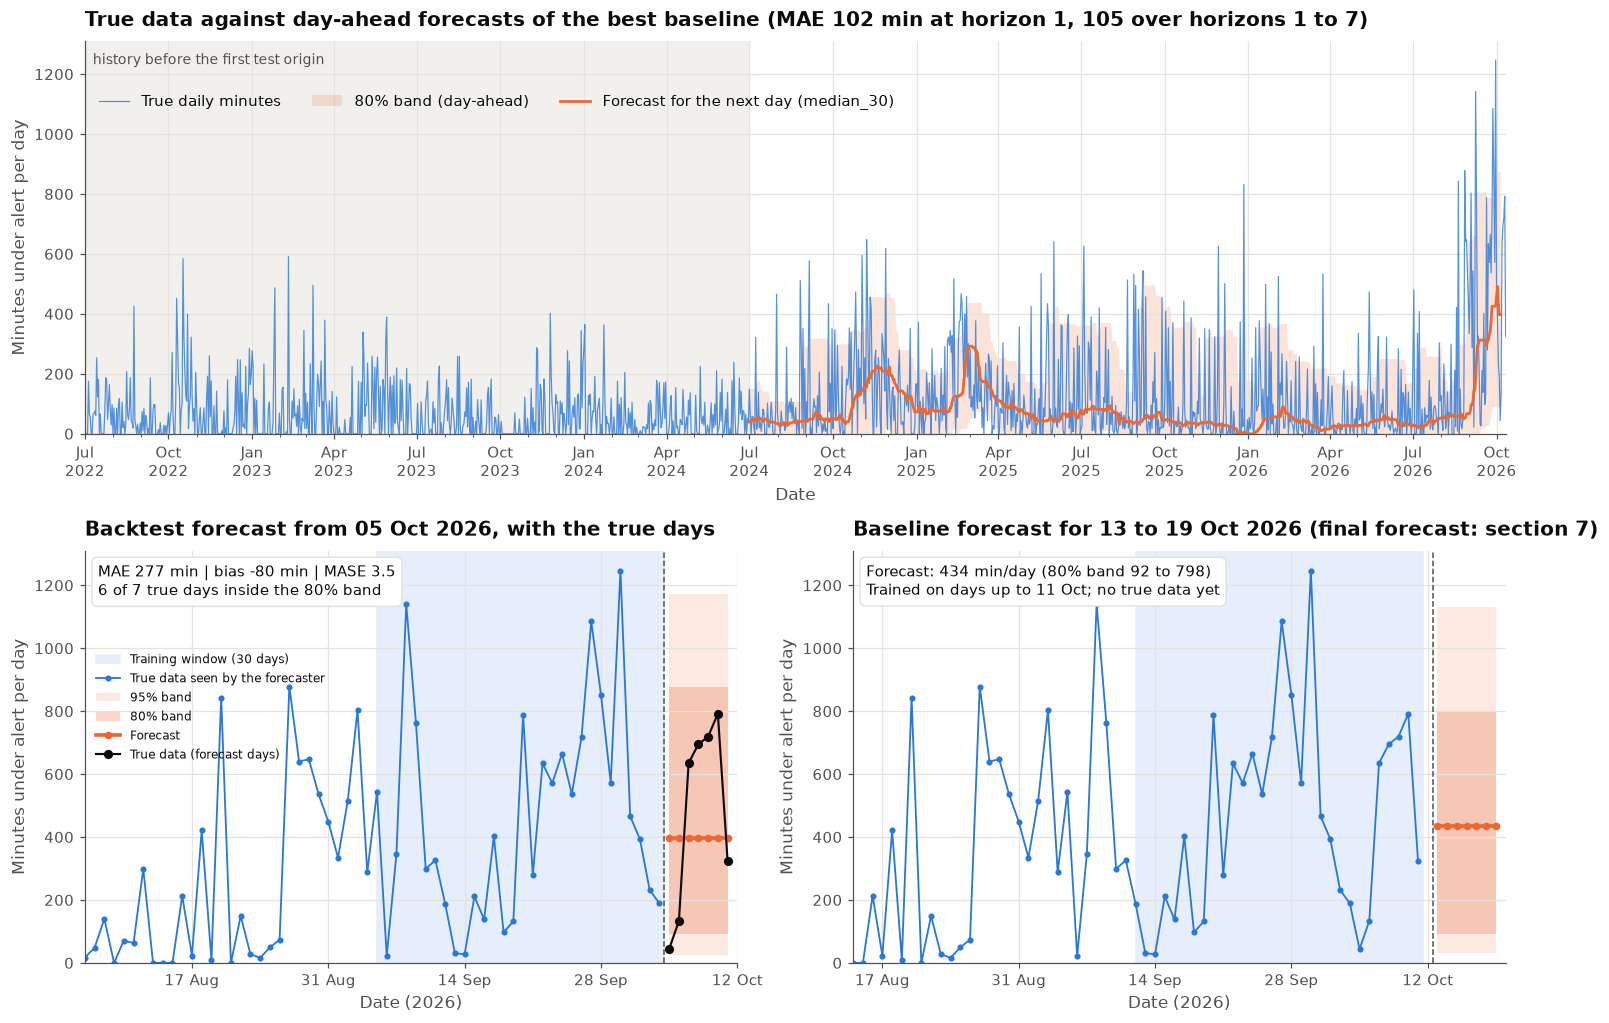

In [25]:
w = bt[bt["method"] == WINNER]
h1 = w[w["h"] == 1].set_index("target")
last_o = w["origin"].max()
one = w[w["origin"] == last_o].set_index("target")
fig = plt.figure(figsize=(14, 9.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])

# top: whole test period, horizon-1 forecasts
ax = fig.add_subplot(gs[0, :])
ax.plot(y_all.index, y_all, color=BLUE, lw=0.8, alpha=0.8, label="True daily minutes")
if h1["q0.1"].notna().any():
    ax.fill_between(h1.index, h1["q0.1"], h1["q0.9"], color=ORANGE, alpha=0.18, lw=0, label="80% band (day-ahead)")
ax.plot(h1.index, h1["point"], color=ORANGE, lw=1.8, label=f"Forecast for the next day ({WINNER})")
ax.axvspan(y_all.index[0], FIRST_TEST_ORIGIN, color="#f1f0ec", zorder=0)
ax.text(y_all.index[0], 0.97, "  history before the first test origin", transform=ax.get_xaxis_transform(), color=MUTED, va="top", fontsize=9)
date_axis(ax, y_all.index[0], y_all.index[-1])
ax.set_ylim(0, None)
mh1 = bk.score(w[w["h"] == 1], SCALE)["mae"].iloc[0]
label(ax, f"True data against day-ahead forecasts of the best baseline (MAE {mh1:.0f} min at horizon 1, {overall.loc[WINNER, 'mae']:.0f} over horizons 1 to 7)",
      "Date", "Minutes under alert per day")
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, 0.9))


def detail(ax, hist, origin, point, q, truth, title, win):
    start = origin - pd.Timedelta(days=win + 30)
    h = hist.loc[start:]
    tg = pd.date_range(origin, periods=len(point), freq="D")
    ax.axvspan(hist.index[-1] - pd.Timedelta(days=(W or len(hist)) - 1), hist.index[-1] + pd.Timedelta(hours=12), color="#e6eefb", zorder=0,
               label=f"Training window ({W if W else 'all'} days)")
    ax.plot(h.index, h, color=BLUE, lw=1.2, marker="o", ms=3, label="True data seen by the forecaster")
    if q is not None:
        ax.fill_between(tg, q[:, 0], q[:, 4], color=ORANGE, alpha=0.14, lw=0, label="95% band")
        ax.fill_between(tg, q[:, 1], q[:, 3], color=ORANGE, alpha=0.26, lw=0, label="80% band")
    ax.plot(tg, point, color=ORANGE, lw=2.4, marker="o", ms=4, label="Forecast")
    if truth is not None:
        ax.plot(tg, truth, color=INK, lw=1.4, marker="o", ms=5, label="True data (forecast days)")
    ax.axvline(origin - pd.Timedelta(hours=12), color=MUTED, lw=1, ls="--")
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: mdates.num2date(x).strftime("%d %b")))
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_xlim(start, tg[-1] + pd.Timedelta(days=1))
    ax.set_ylim(0, None)
    label(ax, title, f"Date ({tg[-1]:%Y})", "Minutes under alert per day")


# bottom left: the latest backtest forecast with known truth
hist_b = y_all.loc[: last_o - pd.Timedelta(days=1)]
qb = one[[f"q{x}" for x in bk.QS]].to_numpy() if one["q0.1"].notna().any() else None
ax1 = fig.add_subplot(gs[1, 0])
detail(ax1, hist_b, last_o, one["point"].to_numpy(), qb, one["y"].to_numpy(), f"Backtest forecast from {last_o:%d %b %Y}, with the true days", W or 90)
e = one["point"] - one["y"]
inside = int(((one["y"] >= one["q0.1"]) & (one["y"] <= one["q0.9"])).sum()) if qb is not None else None
txt = f"MAE {e.abs().mean():.0f} min | bias {e.mean():+.0f} min | MASE {e.abs().mean() / SCALE:.1f}" + (f"\n{inside} of {len(one)} true days inside the 80% band" if inside is not None else "")
ax1.text(0.02, 0.97, txt, transform=ax1.transAxes, va="top", fontsize=10, color=INK,
         bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
ax1.legend(loc="center left", fontsize=8, bbox_to_anchor=(0.0, 0.62))

# bottom right: the real forecast, days that have not happened yet
pt, qq = bk.forecast(y_all, ORIGIN, HORIZON, SPEC)
ax2 = fig.add_subplot(gs[1, 1])
detail(ax2, y_all, ORIGIN, pt, qq, None, f"Baseline forecast for {ORIGIN:%d} to {(ORIGIN + pd.Timedelta(days=HORIZON - 1)):%d %b %Y} (final forecast: section 7)", W or 90)
ax2.text(0.02, 0.97, f"Forecast: {pt[0]:.0f} min/day" + (f" (80% band {qq[0, 1]:.0f} to {qq[0, 3]:.0f})" if qq is not None else "")
         + f"\nTrained on days up to {y_all.index[-1]:%d %b}; no true data yet", transform=ax2.transAxes, va="top", fontsize=10, color=INK,
         bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
plt.tight_layout()

## 6. Models
**Models** (details in `models.py`): ETS(A,N,N) and ARIMA(1,1,1) on the square root of minutes; ridge regression on the square root;
gradient-boosted trees (scikit-learn) with a Poisson loss, which suits skewed, zero-heavy minutes. Ridge and the boosted trees come in two input sets:
`level` (recent-level features, weekday, horizon) and `full` (plus weather on the target day and the holiday features).
Each model is run with several training windows (the last number in its name, in days, or `all`). Feature models are refitted every 7 days.

**Intervals, the same for every method:** the method's own past out-of-sample errors, measured on the scale minutes ** 0.3
(0.3 = 1 - 0.70, the spread-against-level slope), added to the point forecast and transformed back. Bands therefore widen when the level
is high; they are capped at 1,440 minutes (a whole day). The comparison tables use the last 90 days of errors; 6d compares other choices.
On the choice period, the power 0.3 gave better interval scores in the newest level than 0.5, 0.7 or 1.0 (checked once, not tuned further).

**Plan.** 6a runs everything on the same origins as section 5, plus 120 warm-up origins before `FIRST_TEST_ORIGIN` that only feed the
interval errors. 6b chooses the model by the lowest MAE on test targets *before* the last 14 days. 6c and 6d try a forecast combination and
other interval settings. 6e scores the frozen choice on the last 14 days. Section 7 refits it on everything and forecasts.

### 6a. Backtest of every model and baseline (cached per snapshot in `results/`)

In [26]:
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
exo = weather.drop(columns=drop).join(hol, how="left")
WARMUP_START = FIRST_TEST_ORIGIN - pd.Timedelta(days=120)
M_ORIGINS = pd.date_range(WARMUP_START, y_all.index[-1] - pd.Timedelta(days=HORIZON - 1))
CACHE = RESULTS / f"model_backtest_{snap.stem}_v2.pkl"     # one run per snapshot (a few minutes); delete the file to rerun
if CACHE.exists():
    mb = pd.read_pickle(CACHE)
else:
    mb = md.run_models(y_all, exo, M_ORIGINS, HORIZON, progress=lambda s: print(s, flush=True))
    mb.to_pickle(CACHE)
BASELINES = ["last", "same_weekday", "mean_7", "mean_30", "median_14", "median_30", "ewma_7", "mean_all", "median_all"]
bb = bk.run_backtest(y_all, M_ORIGINS, HORIZON, {k: v for k, v in bk.default_methods().items() if k in BASELINES})
warm = pd.concat([mb, bb[mb.columns]], ignore_index=True)       # includes the warm-up origins
# Forecast combinations: a smoother and a fast level average (6c). Adaptive weights use only errors already known at the origin.
COMBOS = {f"comb_{s_.split('_')[0]}_{f_.replace('_', '')}_{w_[:2]}": (s_, f_, w_)
          for s_ in ("ets_sqrt_all", "arima_sqrt_all") for f_ in ("mean_30", "ewma_7") for w_ in ("equal", "adaptive")}
cmb = pd.concat([md.combine(warm, a_, b_, n_, weights=w_, lookback=30) for n_, (a_, b_, w_) in COMBOS.items()], ignore_index=True)
warm = pd.concat([warm, cmb.drop(columns="weight_a")], ignore_index=True)
allbt = md.add_intervals(warm)
allbt = allbt[allbt["origin"] >= FIRST_TEST_ORIGIN].copy()
allbt["slice"] = pd.cut(allbt["target"], edges, right=False, labels=slice_names)
allbt["origin_slice"] = pd.cut(allbt["origin"], edges, right=False, labels=slice_names)
allbt["family"] = allbt["method"].map(lambda m: m.split("_")[0] if m.split("_")[0] in ("ets", "arima", "ridge", "hgb", "comb") else "baseline")
print(f"{allbt['method'].nunique()} methods x {allbt['origin'].nunique()} origins = {len(allbt)} forecast rows")

38 methods x 827 origins = 219982 forecast rows


### 6b. Choice of the model
Lowest MAE on test targets before the last 14 days. The table also shows MAE per level slice and interval coverage (90-day errors).

In [27]:
# Choice: test targets before the last 14 days only
LAST = y_all.index[-1]
CONF_START = LAST - pd.Timedelta(days=13)                 # first day of the 14-day confirmation
sel = allbt[allbt["target"] < CONF_START]
newest = slice_names[-1]
board2 = (bk.score(sel, SCALE)
          .join(bk.score(sel, SCALE, ["method", "slice"])["mae"].unstack().add_prefix("MAE "))
          .join(bk.interval_score(sel)[["cov80", "cov95", "width80"]])
          .join(bk.interval_score(sel, ["method", "slice"]).xs(newest, level="slice")[["cov80", "cov95"]].add_suffix(" newest"))
          .sort_values("mae"))
CHOSEN = board2.index[0]
FROZEN_WINNER = "arima_sqrt_all"     # chosen on the snapshot of 12 Oct 2026; set to None to take whatever is best now
WINNER2 = FROZEN_WINNER or CHOSEN
print(f"Choice on targets up to {CONF_START - pd.Timedelta(days=1):%d %b %Y}: {CHOSEN}" +
      ("" if CHOSEN == WINNER2 else f"  (frozen choice kept: {WINNER2})"))
board2.round(2)

Choice on targets up to 27 Sep 2026: arima_sqrt_all


,mae,mase,rmse,bias,n,MAE before 11 Aug 2024,MAE 11 Aug 2024 to 26 Aug 2026,MAE from 27 Aug 2026,cov80,cov95,width80,cov80 newest,cov95 newest
method,,,,,,,,,,,,,
arima_sqrt_all,101.50,1.28,162.18,-47.13,5712,46.37,94.10,339.41,0.78,0.92,338.55,0.76,0.88
ets_sqrt_all,101.52,1.28,161.43,-45.70,5712,46.79,94.22,336.92,0.79,0.92,339.13,0.77,0.89
ets_sqrt_365,101.66,1.29,161.70,-46.22,5712,46.32,94.41,336.26,0.78,0.92,339.77,0.76,0.88
ets_sqrt_90,102.05,1.29,161.79,-45.75,5712,46.44,94.84,336.34,0.79,0.93,347.13,0.75,0.87
arima_sqrt_365,102.49,1.30,164.35,-48.50,5712,45.90,94.53,355.25,0.78,0.92,339.11,0.74,0.85
arima_sqrt_90,102.70,1.30,163.83,-48.67,5712,45.40,94.94,351.63,0.78,0.92,348.12,0.75,0.84
median_14,102.77,1.30,165.26,-46.61,5712,47.46,94.14,369.75,0.79,0.93,367.78,0.71,0.80
median_30,102.79,1.30,167.99,-53.77,5712,47.06,94.97,351.33,0.79,0.91,370.24,0.69,0.88
ets_sqrt_30,103.19,1.31,160.84,-39.87,5712,47.68,96.76,318.85,0.79,0.93,356.06,0.74,0.88


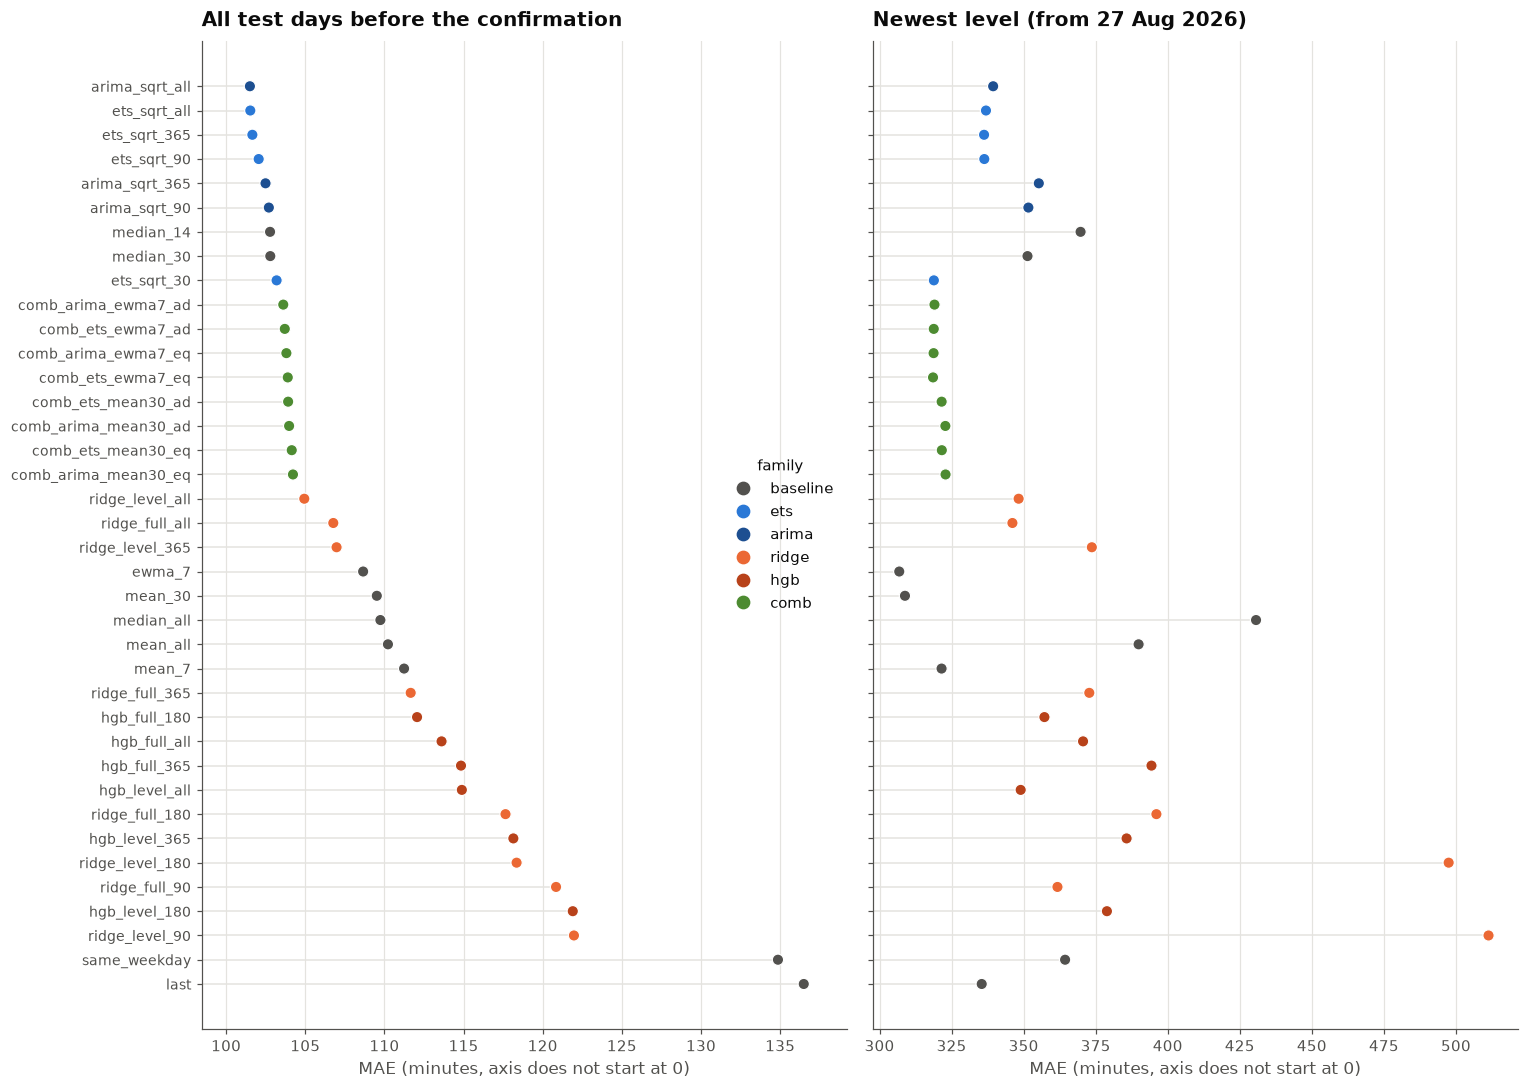

In [28]:
# MAE of every method on the choice period: all slices, and the newest level
fam_col = {"baseline": MUTED, "ets": BLUE, "arima": "#1d4f91", "ridge": ORANGE, "hgb": "#b8421a", "comb": "#4d8b31"}
fams = allbt.drop_duplicates("method").set_index("method")["family"]
order = board2.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 10), sharey=True)
from matplotlib.lines import Line2D
for j, col in enumerate(["mae", f"MAE {newest}"]):
    vals = board2.loc[order, col]
    ax[j].hlines(range(len(order)), vals.min() * 0.97, vals, color=GRID, lw=1)
    ax[j].scatter(vals, range(len(order)), c=[fam_col[fams[m]] for m in order], s=55, zorder=3, edgecolor="white", linewidth=0.8)
    ax[j].set_yticks(range(len(order)), order, fontsize=9)
    ax[j].grid(axis="x", color=GRID, linewidth=0.8)
    ax[j].grid(axis="y", visible=False)
    ax[j].set_xlim(vals.min() * 0.97, vals.max() * 1.02)
    label(ax[j], "All test days before the confirmation" if j == 0 else f"Newest level ({newest})", "MAE (minutes, axis does not start at 0)", "")
ax[0].legend(handles=[Line2D([], [], marker="o", ls="", color=c_, ms=8, label=f_) for f_, c_ in fam_col.items() if f_ in set(fams)],
             loc="center right", title="family")
plt.tight_layout()

In [29]:
# Paired tests on the choice period (per-origin mean absolute error over 7 days, Diebold-Mariano, Newey-West, no multiplicity correction)
loss2 = sel.assign(ae=(sel["point"] - sel["y"]).abs())
full_origins = loss2.groupby("origin")["h"].count()
loss2 = loss2[loss2["origin"].isin(full_origins[full_origins == HORIZON * loss2["method"].nunique()].index)]
L = loss2.groupby(["method", "origin"])["ae"].mean().unstack(0)
osl = loss2.drop_duplicates("origin").set_index("origin")["origin_slice"]
best_base = board2[board2.index.isin(BASELINES)].index[0]
pairs2 = [(WINNER2, m) for m in list(board2.index[1:4]) + [best_base, "mean_30", "ewma_7"] if m != WINNER2]
pairs2 += [("ridge_full_all", "ridge_level_all"), ("hgb_full_all", "hgb_level_all")]
pairs2 = [(p, q) for p, q in pairs2 if p in L.columns and q in L.columns]
rows2 = []
for a_, b_ in dict.fromkeys(pairs2):
    for name, mask in [("all", slice(None)), (newest, osl == newest)]:
        mu, st, p = bk.dm_test(L.loc[mask, a_].to_numpy(), L.loc[mask, b_].to_numpy(), lags=HORIZON - 1)
        rows2.append({"a": a_, "b": b_, "origins": name, "n": int(np.sum(mask)) if name != "all" else len(L),
                      "mean diff a-b (min)": mu, "p-value": p})
pd.DataFrame(rows2).round(3)

,a,b,origins,n,mean diff a-b (min),p-value
0,arima_sqrt_all,ets_sqrt_all,all,813,-0.052,0.868
1,arima_sqrt_all,ets_sqrt_all,from 27 Aug 2026,26,1.792,0.831
2,arima_sqrt_all,ets_sqrt_365,all,813,-0.196,0.583
3,arima_sqrt_all,ets_sqrt_365,from 27 Aug 2026,26,2.747,0.788
4,arima_sqrt_all,ets_sqrt_90,all,813,-0.747,0.311
5,arima_sqrt_all,ets_sqrt_90,from 27 Aug 2026,26,-1.900,0.929
6,arima_sqrt_all,median_14,all,813,-1.122,0.404
7,arima_sqrt_all,median_14,from 27 Aug 2026,26,-28.551,0.305
8,arima_sqrt_all,mean_30,all,813,-8.436,0.000
9,arima_sqrt_all,mean_30,from 27 Aug 2026,26,19.957,0.134


**Reading of 6b (snapshot of 12 Oct 2026).** `arima_sqrt_all` has the lowest MAE on the choice period (101.5 minutes), but it is a tie:
`ets_sqrt_all` is 0.02 minutes behind (p = 0.87) and the top nine (ETS, ARIMA, 14- and 30-day medians) are within about 2 minutes with no
significant difference. They beat the 30-day mean and the 7-day half-life average by about 8 minutes over all test days (p < 0.001).
In the newest level the order flips: the 30-day mean and the 7-day average are about 20 minutes better, but on 26 origins that is not
significant (p = 0.13 and 0.48).

**Feature models do not help yet.** The best ridge (`ridge_level_all`, 104.9) and the best boosted trees (`hgb_full_180`, 112.1) are behind
the simple smoothers. Short windows hurt them most (ridge with 90 days: about 121). **Weather and holidays add nothing measurable:** ridge with
them is 1.9 minutes worse (p = 0.009); the boosted trees with them are 1.4 minutes better over all test days (p = 0.34, not significant)
but 24 minutes worse in the newest level (p < 0.001 on only 26 origins).

**Intervals with 90-day errors.** The bands cover 78 to 79% (80% band) and 92% (95% band) over all test days, slightly under nominal.
In the newest level the chosen model's bands cover 76% and 88%: far better than bands from the whole history (about 30% and 50% in
section 5), but still a little low. 6d tries to improve this.

### 6c. Forecast combination: a smoother and a fast level average
Over the whole test period the smoothers (ETS, ARIMA) win; in the newest level the fast averages (30-day mean, 7-day half-life) win.
A combination `w x smoother + (1 - w) x fast average` hedges between the two. `eq`: w = 0.5. `ad` (adaptive): w = (1/MAE_a) / (1/MAE_a + 1/MAE_b),
with each MAE over the forecasts whose target day fell in the 30 days before the origin, so the weight moves towards whichever did better lately.

In [30]:
comb_names = list(COMBOS)
BEST_COMB = board2.loc[comb_names, "mae"].idxmin()
show = [WINNER2] + comb_names + ["ets_sqrt_all", "mean_30", "ewma_7"]
show = list(dict.fromkeys(m for m in show if m in board2.index))
print(f"Best combination on the choice period: {BEST_COMB}")
display_cols = ["mae", "rmse", "bias", f"MAE {newest}", "cov80", "cov95"]
rows3 = []
for name, mask in [("all", slice(None)), (newest, osl == newest)]:
    for c_ in [BEST_COMB, f"{BEST_COMB[:-3]}_eq" if BEST_COMB.endswith("_ad") else f"{BEST_COMB[:-3]}_ad"]:
        mu, st, p = bk.dm_test(L.loc[mask, WINNER2].to_numpy(), L.loc[mask, c_].to_numpy(), lags=HORIZON - 1)
        rows3.append({"a": WINNER2, "b": c_, "origins": name, "mean diff a-b (min)": mu, "p-value": p})
print(pd.DataFrame(rows3).round(3).to_string())
board2.loc[show, display_cols].round(2)

Best combination on the choice period: comb_arima_ewma7_ad
                a                    b           origins  mean diff a-b (min)  p-value
0  arima_sqrt_all  comb_arima_ewma7_ad               all               -2.258    0.007
1  arima_sqrt_all  comb_arima_ewma7_eq               all               -2.451    0.004
2  arima_sqrt_all  comb_arima_ewma7_ad  from 27 Aug 2026               16.598    0.326
3  arima_sqrt_all  comb_arima_ewma7_eq  from 27 Aug 2026               17.020    0.303


,mae,rmse,bias,MAE from 27 Aug 2026,cov80,cov95
method,,,,,,
arima_sqrt_all,101.50,162.18,-47.13,339.41,0.78,0.92
comb_ets_mean30_eq,104.14,157.00,-27.38,321.60,0.78,0.92
comb_ets_mean30_ad,103.92,157.15,-28.34,321.54,0.78,0.92
comb_ets_ewma7_eq,103.89,156.13,-26.37,318.55,0.78,0.93
comb_ets_ewma7_ad,103.70,156.27,-27.17,318.81,0.78,0.93
comb_arima_mean30_eq,104.22,157.42,-28.09,322.89,0.78,0.92
comb_arima_mean30_ad,103.98,157.54,-29.01,322.83,0.78,0.92
comb_arima_ewma7_eq,103.80,156.30,-27.09,318.75,0.78,0.92
comb_arima_ewma7_ad,103.61,156.43,-27.84,319.05,0.78,0.92


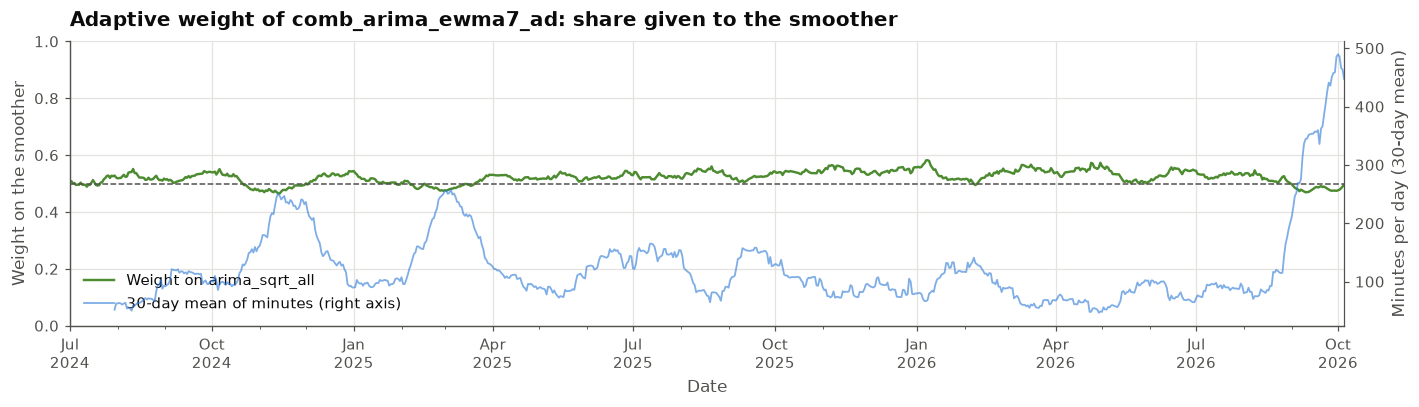

In [31]:
# How the adaptive weight on the smoother moved over time (horizon 1), against the level of the series
ad_name = BEST_COMB if BEST_COMB.endswith("_ad") else f"{BEST_COMB[:-3]}_ad"
wt = cmb[(cmb["method"] == ad_name) & (cmb["h"] == 1) & (cmb["origin"] >= FIRST_TEST_ORIGIN)].set_index("origin")["weight_a"]
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(wt.index, wt, color="#4d8b31", lw=1.6, label=f"Weight on {COMBOS[ad_name][0]}")
ax.axhline(0.5, color=MUTED, lw=1, ls="--")
ax.set_ylim(0, 1)
ax2 = ax.twinx()
ax2.plot(y_all.loc[FIRST_TEST_ORIGIN:].rolling(30).mean(), color=BLUE, lw=1.2, alpha=0.6, label="30-day mean of minutes (right axis)")
ax2.set_ylabel("Minutes per day (30-day mean)")
ax2.spines["right"].set_visible(True)
ax2.grid(False)
date_axis(ax, wt.index[0], wt.index[-1])
label(ax, f"Adaptive weight of {ad_name}: share given to the smoother", "Date", "Weight on the smoother")
h1_, l1_ = ax.get_legend_handles_labels()
h2_, l2_ = ax2.get_legend_handles_labels()
ax.legend(h1_ + h2_, l1_ + l2_, loc="lower left")
plt.tight_layout()

**Reading of 6c.** The best combination is `comb_arima_ewma7_ad` (ARIMA on the square root with the 7-day half-life average, adaptive
weights). Over all test days it is 2.3 minutes worse than ARIMA alone (MAE 103.6 against 101.5, p = 0.007). In the newest level it is 17
minutes better (319 against 339, p = 0.33 on 26 origins, not significant). It has a lower RMSE (156 against 162) and half the bias
(-28 against -47). The adaptive weight hardly moves (0.47 to 0.58), so adaptive and equal weights give almost the same forecasts.
By the rule fixed earlier (lowest MAE), ARIMA stays the choice. The combination is the reasonable alternative if the newest level
matters most: set `FINAL_METHOD = BEST_COMB` in section 7.

### 6d. Intervals in the newest level: shorter look-back or regime-aware errors
Every configuration builds the bands from the method's own past errors (scale minutes ** 0.3, capped at 1,440 minutes); they differ in which errors:
`recent N`: errors on targets in the last N days. `level N xR`: errors from the last N days whose point forecast was within a factor R of the
current one (a high forecast borrows errors from high-level days). Judged by the interval score (80% plus 95%; lower is better) on the choice period.
Rule: among configurations whose 80% band covers at least 75% of days in the newest level, take the lowest interval score over all test days.
The rule was written after seeing the comparison below, so treat the choice as a judgement, not a test.

In [32]:
IV_CFGS = {
    "recent 30": dict(mode="recent", lookback=30), "recent 45": dict(mode="recent", lookback=45),
    "recent 60": dict(mode="recent", lookback=60), "recent 90": dict(mode="recent", lookback=90),
    "level 180 x2": dict(mode="level", lookback=180, ratio=2.0), "level 365 x1.5": dict(mode="level", lookback=365, ratio=1.5),
    "level 365 x2": dict(mode="level", lookback=365, ratio=2.0), "level 730 x1.5": dict(mode="level", lookback=730, ratio=1.5),
}
iv_methods = list(dict.fromkeys([WINNER2, BEST_COMB]))
warm_sub = warm[warm["method"].isin(iv_methods)]
rows4 = []
for cname, cfg in IV_CFGS.items():
    x = md.add_intervals(warm_sub, **cfg)
    x = x[(x["origin"] >= FIRST_TEST_ORIGIN) & (x["target"] < CONF_START)]
    for part, xx in [("all", x), ("newest", x[x["target"] >= edges[-2]])]:
        s_ = bk.interval_score(xx)
        for m_ in s_.index:
            rows4.append({"config": cname, "method": m_, "part": part, "cov80": s_.loc[m_, "cov80"], "cov95": s_.loc[m_, "cov95"],
                          "score": s_.loc[m_, "is80"] + s_.loc[m_, "is95"]})
ivtab = pd.DataFrame(rows4).pivot_table(index=["method", "config"], columns="part", values=["cov80", "cov95", "score"])
w_tab = ivtab.loc[WINNER2]
ok_cfg = w_tab[w_tab[("cov80", "newest")] >= 0.75]
IV_NAME = (ok_cfg if len(ok_cfg) else w_tab)[("score", "all")].idxmin()
IV_CFG = IV_CFGS[IV_NAME]
print(f"Interval configuration chosen for {WINNER2}: {IV_NAME} {IV_CFG}")
allbt2 = md.add_intervals(warm, **IV_CFG)
allbt2 = allbt2[allbt2["origin"] >= FIRST_TEST_ORIGIN]
ivtab.round(2)

Interval configuration chosen for arima_sqrt_all: recent 60 {'mode': 'recent', 'lookback': 60}


cov80        cov95           score         
part                                 all newest   all newest      all   newest
method              config                                                    
arima_sqrt_all      level 180 x2    0.79   0.64  0.94   0.81  1196.29  3633.80
                    level 365 x1.5  0.80   0.67  0.95   0.82  1186.12  3600.57
                    level 365 x2    0.79   0.66  0.94   0.81  1179.29  3523.94
                    level 730 x1.5  0.79   0.44  0.94   0.75  1232.60  4467.63
                    recent 30       0.78   0.83  0.93   1.00  1232.95  2844.38
                    recent 45       0.79   0.80  0.92   0.90  1244.06  3595.72
                    recent 60       0.79   0.79  0.93   0.92  1203.58  3174.97
                    recent 90       0.78   0.76  0.92   0.88  1227.76  3405.83
comb_arima_ewma7_ad level 180 x2    0.79   0.64  0.94   0.81  1183.44  3465.63
                    level 365 x1.5  0.80   0.69  0.95   0.84  1169.91  3311.77
                    level 365 x2    0.79   0.67  0.95   0.83  1157.50  3242.85
                    level 730 x1.5  0.78   0.47  0.95   0.79  1208.82  4032.97
                    recent 30       0.78   0.86  0.93   1.00  1228.07  2756.99
                    recent 45       0.79   0.81  0.93   0.91  1231.03  3331.42
                    recent 60       0.79   0.81  0.93   0.94  1190.53  2916.22
                    recent 90       0.78   0.79  0.92   0.90  1208.02  3120.76

**Reading of 6d.** Regime-aware errors (`level 365 x2`) give the best interval score over all test days (1,179) and the right coverage
there (79% and 94%), but in the newest level they cover only 66% and 81%: there are few past high-level forecasts to borrow errors from.
The 30-day look-back covers the newest level well (83% and 100%) but scores worse overall. The chosen `recent 60` covers 79% and 93%
overall and 79% and 92% in the newest level, and its interval score is lower than the 90-day look-back both overall (1,204 against 1,228)
and in the newest level (3,175 against 3,406).

### 6e. Confirmation on the last 14 days
The frozen choice, scored on the two weekly forecasts made 14 and 7 days before the newest complete day, with the bands chosen in 6d.
Other methods are shown for context only; nothing is re-chosen here.

In [33]:
CONF_ORIGINS = [CONF_START, CONF_START + pd.Timedelta(days=7)]
conf = allbt2[allbt2["origin"].isin(CONF_ORIGINS)]
ctab = (bk.score(conf, SCALE).join(bk.interval_score(conf)[["cov80", "cov95"]])
        .loc[list(dict.fromkeys([WINNER2, BEST_COMB] + [m for m in [board2.index[1], best_base, "mean_30", "ewma_7"] if m != WINNER2]))])
print(f"Bands: {IV_NAME}")
print(f"Confirmation days: {CONF_START:%d %b} to {LAST:%d %b %Y} (14 days, 2 origins)")
ctab.round(2)

Bands: recent 60
Confirmation days: 28 Sep to 11 Oct 2026 (14 days, 2 origins)


,mae,mase,rmse,bias,n,cov80,cov95
method,,,,,,,
arima_sqrt_all,269.67,3.41,333.18,-101.13,14,0.93,1.0
comb_arima_ewma7_ad,265.03,3.35,323.24,-56.59,14,0.93,1.0
ets_sqrt_all,268.50,3.40,326.98,-69.53,14,0.93,1.0
median_14,259.11,3.28,329.92,-0.75,14,0.93,1.0
mean_30,267.74,3.39,326.31,-64.20,14,0.93,1.0
ewma_7,266.06,3.37,319.72,-14.79,14,1.00,1.0


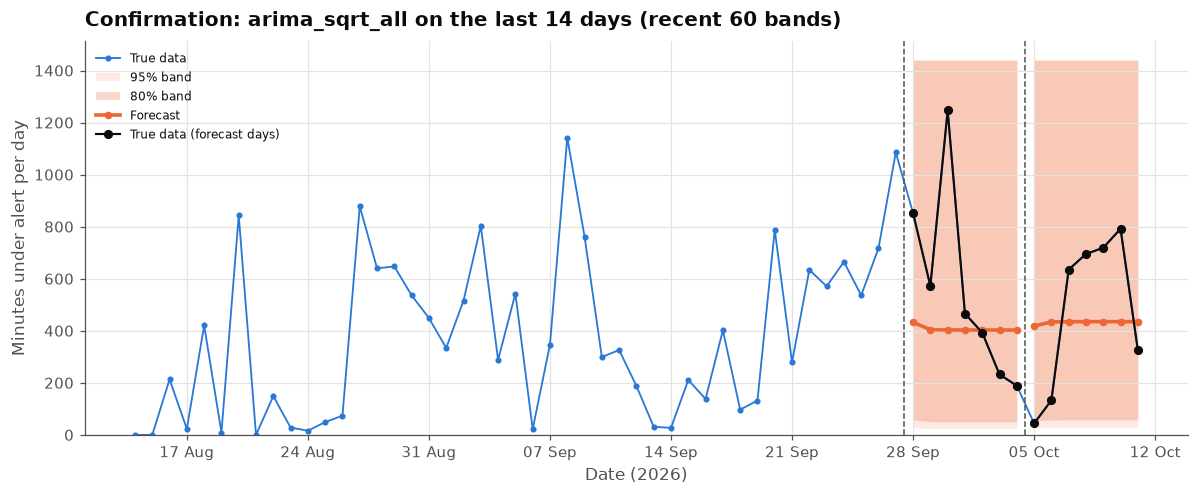

In [34]:
def forecast_panel(ax, hist, rows_list, title, show_truth=True):
    start = rows_list[0]["target"].min() - pd.Timedelta(days=45)
    h = hist.loc[start:]
    ax.plot(h.index, h, color=BLUE, lw=1.2, marker="o", ms=3, label="True data")
    for i, r in enumerate(rows_list):
        r = r.sort_values("target")
        ax.fill_between(r["target"], r["q0.025"], r["q0.975"], color=ORANGE, alpha=0.13, lw=0, label="95% band" if i == 0 else None)
        ax.fill_between(r["target"], r["q0.1"], r["q0.9"], color=ORANGE, alpha=0.26, lw=0, label="80% band" if i == 0 else None)
        ax.plot(r["target"], r["point"], color=ORANGE, lw=2.4, marker="o", ms=4, label="Forecast" if i == 0 else None)
        ax.axvline(r["origin"].iloc[0] - pd.Timedelta(hours=12), color=MUTED, lw=1, ls="--")
        if show_truth and r["y"].notna().any():
            ax.plot(r["target"], r["y"], color=INK, lw=1.4, marker="o", ms=5, label="True data (forecast days)" if i == 0 else None)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: mdates.num2date(x).strftime("%d %b")))
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_ylim(0, None)
    label(ax, title, "Date (2026)" if h.index[-1].year == 2026 else "Date", "Minutes under alert per day")
    ax.legend(loc="upper left", fontsize=8)


fig, ax = plt.subplots(figsize=(11, 4.6))
forecast_panel(ax, y_all, [allbt2[(allbt2["method"] == WINNER2) & (allbt2["origin"] == o)] for o in CONF_ORIGINS],
               f"Confirmation: {WINNER2} on the last 14 days ({IV_NAME} bands)")
plt.tight_layout()

**Reading of 6e.** ARIMA: MAE 270 minutes, bias -101 (too low); 13 of 14 days fall inside the 80% band and all 14 inside the 95% band.
The combination scores MAE 265 with bias -57, and the other references 259 to 268 on the same days: 14 days cannot separate methods
this close, as expected.

## 7. The forecast for the next 7 days
The frozen choice (`FINAL_METHOD`, by default `WINNER2`) is refitted on all complete days and forecasts the 7 days from `ORIGIN`, with
bands from its own errors as chosen in 6d. The best combination is shown next to it. The table is saved to
`results/forecast_<origin>_<method>.csv`.

Trained on complete days up to 11 Oct 2026; forecast from 12 Oct, shown from 13 Oct. Saved forecast_20261013_arima_sqrt_all.csv


,date,forecast_min,lo80,hi80,lo95,hi95,comb_arima_ewma7_ad_min,comb_arima_ewma7_ad_lo80,comb_arima_ewma7_ad_hi80
0,2026-10-13,437.0,57.0,1440.0,30.0,1440.0,471.0,47.0,1440.0
1,2026-10-14,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0
2,2026-10-15,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0
3,2026-10-16,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0
4,2026-10-17,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0
5,2026-10-18,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0
6,2026-10-19,437.0,57.0,1440.0,30.0,1440.0,472.0,47.0,1440.0


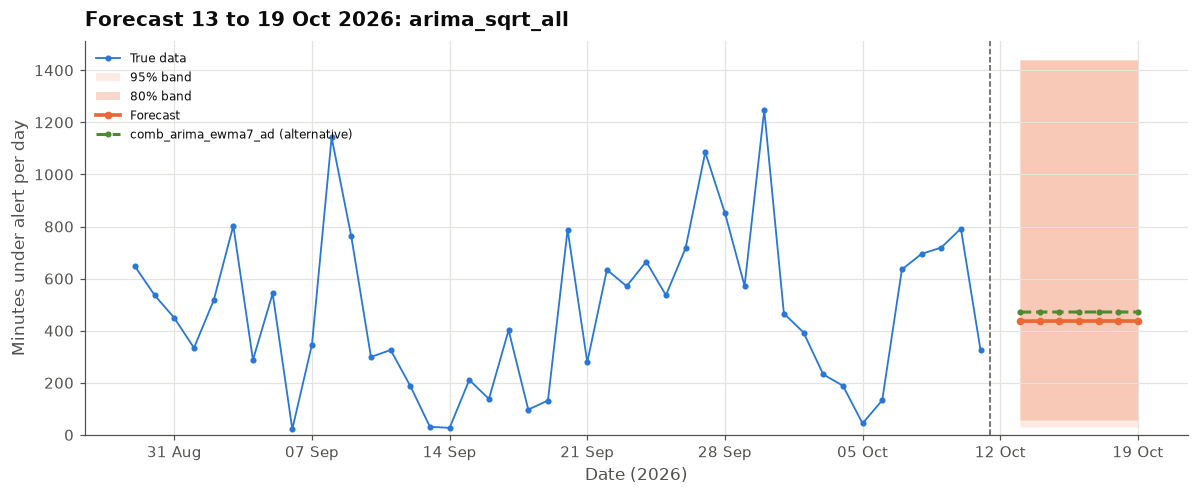

In [35]:
# Refit on all complete days. If the newest complete day is not the day before ORIGIN (snapshot taken during the day),
# the model forecasts from the day after the newest complete day and the first day is dropped.
ORIGIN_EFF = LAST + pd.Timedelta(days=1)
H_EFF = (ORIGIN - ORIGIN_EFF).days + HORIZON
BASE_SPECS = bk.default_methods()


def final_point(name):
    if name in COMBOS:
        a_, b_, w_ = COMBOS[name]
        w = md.combine_weight(warm, a_, b_, ORIGIN_EFF, weights=w_, lookback=30)
        return w * final_point(a_) + (1 - w) * final_point(b_)
    if name in BASE_SPECS:
        return bk.forecast(y_all, ORIGIN_EFF, H_EFF, BASE_SPECS[name])[0]
    return md.forecast_final(name, y_all, exo, ORIGIN_EFF, H_EFF)


def final_frame(name):
    p_ = final_point(name)
    q_ = md.band(p_, md.recent_errors(warm, name, ORIGIN_EFF, point_now=float(np.mean(p_)), **IV_CFG))
    f_ = pd.DataFrame({"origin": ORIGIN_EFF, "target": pd.date_range(ORIGIN_EFF, periods=H_EFF), "point": p_, "y": np.nan}
                      | {f"q{q}": q_[:, j] for j, q in enumerate(bk.QS)})
    return f_[f_["target"] >= ORIGIN].reset_index(drop=True)


FINAL_METHOD = WINNER2            # the frozen choice; set to BEST_COMB to publish the combination instead
fc = final_frame(FINAL_METHOD)
fc_c = final_frame(BEST_COMB)
out = fc.rename(columns={"target": "date", "point": "forecast_min", "q0.025": "lo95", "q0.1": "lo80",
                         "q0.9": "hi80", "q0.975": "hi95"})[["date", "forecast_min", "lo80", "hi80", "lo95", "hi95"]]
out[f"{BEST_COMB}_min"] = fc_c["point"].to_numpy()
out[f"{BEST_COMB}_lo80"] = fc_c["q0.1"].to_numpy()
out[f"{BEST_COMB}_hi80"] = fc_c["q0.9"].to_numpy()
out[out.columns[1:]] = out[out.columns[1:]].round(0)
out_path = RESULTS / f"forecast_{ORIGIN:%Y%m%d}_{FINAL_METHOD}.csv"
out.to_csv(out_path, index=False)

fig, ax = plt.subplots(figsize=(11, 4.6))
forecast_panel(ax, y_all, [fc], f"Forecast {ORIGIN:%d} to {(ORIGIN + pd.Timedelta(days=HORIZON - 1)):%d %b %Y}: {FINAL_METHOD}", show_truth=False)
ax.plot(fc_c["target"], fc_c["point"], color="#4d8b31", lw=2, ls="--", marker="o", ms=3, label=f"{BEST_COMB} (alternative)")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
print(f"Trained on complete days up to {LAST:%d %b %Y}; forecast from {ORIGIN_EFF:%d %b}, shown from {ORIGIN:%d %b}. Saved {out_path.name}")
out

**Reading of 7 (snapshot of 12 Oct 2026).** ARIMA forecasts about 437 minutes per day, flat over the week; the combination about 471.
The lower 80% bounds are about 57 and 47 minutes. The upper bounds reach the 1,440-minute cap, because the last 60 days of errors include
the late-August jump, when forecasts were far too low: read them as "a full-alert day is possible", not as a precise number. Both point
forecasts are below the newest level's mean (485), in line with the negative bias in the backtest and the confirmation. The snapshot was
taken during 12 Oct, so the model forecasts from 12 Oct and that day is dropped from the table.

**Make a new forecast.** Fetch a fresh snapshot and the weather, ideally shortly after midnight Kyiv time, so that the day before the
origin is complete:
```
uv run python kyiv_digital.py fetch
uv run python weather.py fetch
```
Then restart the kernel and run all cells. The newest snapshot is picked up, the model backtest is recomputed once for it (a few minutes,
cached in `results/`), and the frozen choice in `FROZEN_WINNER` is kept.

## 8. Summary, caveats and further work
**What the data show (sections 4 and 4b).** Minutes under alert per day are skewed (42% of days without an alert before July 2024) and their
level shifted twice: about 64 minutes per day until 10 Aug 2024, 114 until 26 Aug 2026, and 485 since 27 Aug 2026. Heavy days follow the
level rather than each other, long alerts drive heavy days more than many alerts, and the day-to-day spread grows with the level (slope 0.70).

**What forecasts well (sections 5 and 6).** Simple level forecasters beat everything with more inputs. Over 827 test origins (Jul 2024 to
Oct 2026), ETS and ARIMA on the square root and the 14- and 30-day medians are within about 2 minutes of each other (MAE about 101 to 103
minutes per day, MASE about 1.3). Ridge and boosted trees with recent-level, weekday, weather and holiday inputs are behind (MAE 105 to 122),
and weather and holidays add nothing measurable. In the newest level the short averages (30-day mean, 7-day half-life) do best; a combination
of ARIMA and the 7-day average hedges between the two.

**Intervals.** Bands from each method's own past errors, on the scale minutes ** 0.3 with a 60-day look-back, cover 79% and 93% of days
(80% and 95% bands) over the whole test period and 79% and 92% in the newest level.

**Forecast (section 7).** About 437 minutes per day for 13 to 19 Oct 2026 from ARIMA (471 from the combination), with an 80% interval from
about 57 minutes to a whole day.

**Caveats**
- The model choice is a near tie and was made on the same test period it is reported on, so the reported errors are slightly optimistic.
- The newest level has only 46 days of history; its p-values rest on 26 to 40 heavily overlapping origins and are not corrected for the
  number of comparisons.
- Weather in the backtest comes from archived same-day forecasts, which flatters weather at horizons 2 to 7 (it still did not help).
- The interval rule in 6d was written after seeing the comparison; the power 0.3 was compared once with 0.5, 0.7 and 1.0.
- Section 4b used the full history, test period included, to find the level shifts. No forecaster uses them, but they shaped the methods tried.
- Limitations of the alert source (unofficial page, unknown publication lag, possible change in how alerts are recorded since Aug 2026) are
  listed in the README (L1 to L21).

**Further work**
- Regime-switching models (Markov switching) and pretrained time-series models; Holm correction or a Model Confidence Set for the comparisons.
- Neighbouring-region alerts and threat types from another source (Kyiv Digital covers Kyiv City only, without threat type).
- Regular snapshots to measure revisions and publication lag, and a weekly forecast scored when its week is over.
- The onset question (chance of an alert in a given hour) and the duration question, on the same series and backtest.